In [1]:
import os
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
_SRC = _ROOT / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))
os.chdir(_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import random
import symba
from symba import *
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import contextlib
import pickle
from collections import defaultdict
import time

# All random steps (synthetic data, noise, shuffles, ordering of simultaneous
# events) are seeded, so re-running a section reproduces its results.
SEED = 0
symba.set_seed(SEED)

# True: rerun every simulation (several hours in total); False: use the results shipped in data/.
# Each section also has its own switch (e.g. RECOMPUTE_NOISE) that defaults to this value.
RECOMPUTE = False

# Figures made by this notebook are saved here (not tracked by git);
# figures/ holds the reference copies of the figures in the paper.
FIG_DIR = "outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)


In [2]:
# reload edits to src/symba/ without restarting the kernel
%load_ext autoreload
%autoreload 2


In [3]:
def evaluate_symba_across_noise_prob_with_error(
    p_values, n_runs=5, noise_type='substitution', nsr_fixed=10, ordered_words=0,
    alph_length=20, num_2words=10, num_3words=10, num_4words=10,
    rep_2words=10, rep_3words=10, rep_4words=10, gamma=1,
    spacebar=1, space_weight=10, time_bin=2, max_size=4,
    positive_js=1, smooth_epsilon=1,
    quantiles_list=(0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                    0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99),
    with_space=1
):
    """
    Evaluates SYMBA across symbol-noise probabilities, repeating n_runs times to get mean and std dev.
    noise_type: 'substitution' or 'deletion'
    """

    # We will store the summary statistics here
    summary_data = {
        2: {'mean_f1': [], 'std_f1': [], 'mean_auc': [], 'std_auc': []},
        3: {'mean_f1': [], 'std_f1': [], 'mean_auc': [], 'std_auc': []},
        4: {'mean_f1': [], 'std_f1': [], 'mean_auc': [], 'std_auc': []}
    }

    for p in p_values:
        print(f"Processing p_{noise_type} = {p:.3f} (over {n_runs} runs)...")

        p_sub = p if noise_type == 'substitution' else 0.0
        p_remove = p if noise_type == 'deletion' else 0.0

        # Temporary lists to hold the results of each run for this specific p
        run_results = {2: {'f1': [], 'auc': []}, 3: {'f1': [], 'auc': []}, 4: {'f1': [], 'auc': []}}

        for run in range(n_runs):
            # === Generate synthetic data ===
            hyper_seq, spike_seq, words_in_sentence_per_size_dict, _ = generate_synthetic_sequence(
                alph_length=alph_length, num_unique_2words=num_2words,
                num_unique_3words=num_3words, num_unique_4words=num_4words,
                rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words,
                nsr=nsr_fixed, gamma=gamma, spacebar=spacebar, space_weight=space_weight,
                ordered_words=ordered_words, time_bin=time_bin, different_alphabet=0,
                p_sub=p_sub, p_remove=p_remove
            )

            observed_counts, expected_probs = symba.observed_counts_and_expected_probs(
                hyper_seq, spike_seq, max_size=max_size, ordered_words=ordered_words
            )

            count2, count3, count4 = 0, 0, 0
            for word in observed_counts.keys():
                if len(word) == 2: count2 += 1
                if len(word) == 3: count3 += 1
                if len(word) == 4: count4 += 1

            # === Compute SYMBA ===
            js_dict = symba.js_score_per_size(
                hyper_seq, observed_counts, expected_probs,
                max_size = max_size, positive_js = positive_js,
                smooth_prior=smooth_epsilon,
                number_of_points=0,
                quantiles_list=quantiles_list, with_space=with_space
            )

            # === Store PR metrics for this run ===
            for length in [2, 3, 4]:
                res = compute_pr_and_roc(
                    js_dict, words_in_sentence_per_size_dict, length, count2, count3, count4
                )
                run_results[length]['f1'].append(res['best_f1'])
                run_results[length]['auc'].append(res['auc_pr'])

        # After all runs for this 'p', calculate mean and standard deviation
        for length in [2, 3, 4]:
            summary_data[length]['mean_f1'].append(np.mean(run_results[length]['f1']))
            summary_data[length]['std_f1'].append(np.std(run_results[length]['f1']))
            summary_data[length]['mean_auc'].append(np.mean(run_results[length]['auc']))
            summary_data[length]['std_auc'].append(np.std(run_results[length]['auc']))

    return summary_data


#### Robustness to symbol noise (substitution and deletion)

##### Independent runs for each motif length

In [4]:
### Parameters of the noise-robustness experiment
# Only motifs of one length k are planted per simulation (independent runs for k = 2, 3, 4).
alph_length = 20
num_words = 20             # distinct motifs of length k
rep_words = 30             # repetitions of each motif
nsr_fixed = 10             # noise-to-signal ratio
ordered_words_noise = 0    # unordered motifs; set to 1 (with RECOMPUTE_NOISE = True) for the ordered-motif version
gamma = 1                  # Zipf exponent of the background noise
spacebar = 0
space_weight = 10
time_bin = 2
max_size = 4
pword_max = 0.9            # largest word-corruption probability p_w in the sweep
n_runs_noise = 30

# SYMBA scoring parameters
with_space = 0
positive_js = 1
smooth_epsilon = 1.
quantiles_list1 = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                   0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

noise_types = ['substitution', 'deletion']
RECOMPUTE_NOISE = RECOMPUTE  # True: rerun the sweep (slow); False: use the results shipped in data/

def noise_results_path(noise_type):
    return (f"data/aggregated_results_{noise_type}_alph{alph_length}_g{gamma}"
            f"_n{num_words}_r{rep_words}_ord{ordered_words_noise}_nsr{nsr_fixed}.pkl")


In [5]:
if RECOMPUTE_NOISE:
    symba.set_seed(SEED)
    for noise_type in noise_types:
        aggregated_results = {}
        for k in [2, 3, 4]:
            print(f"--- {noise_type}: independent simulation for length {k} ---")

            # 1. p_s sweep up to the value giving a word-corruption probability of pword_max
            psymb_max = 1 - (1 - pword_max)**(1/k)
            p_sweep = np.linspace(0.0, psymb_max, 11)

            # 2. Isolate the generation: only activate motifs of length k
            n = {L: (num_words if L == k else 0) for L in (2, 3, 4)}
            r = {L: (rep_words if L == k else 0) for L in (2, 3, 4)}

            # 3. Run the evaluation silently
            with contextlib.redirect_stdout(open(os.devnull, 'w')):
                summary_results = evaluate_symba_across_noise_prob_with_error(
                    p_values=p_sweep, n_runs=n_runs_noise, noise_type=noise_type,
                    nsr_fixed=nsr_fixed, ordered_words=ordered_words_noise,
                    alph_length=alph_length,
                    num_2words=n[2], num_3words=n[3], num_4words=n[4],
                    rep_2words=r[2], rep_3words=r[3], rep_4words=r[4],
                    gamma=gamma, spacebar=spacebar, space_weight=space_weight,
                    time_bin=time_bin, max_size=max_size,
                    positive_js=positive_js, smooth_epsilon=smooth_epsilon,
                    quantiles_list=quantiles_list1, with_space=with_space
                )

            # 4. Keep the results for length k, with its own p_s sweep
            aggregated_results[k] = summary_results[k]
            aggregated_results[k]['p_s_values'] = p_sweep

        with open(noise_results_path(noise_type), 'wb') as f:
            pickle.dump(aggregated_results, f)
        print(f"Saved: {noise_results_path(noise_type)}")


In [6]:
aggregated_results_dict = {}
for noise_type in noise_types:
    with open(noise_results_path(noise_type), 'rb') as f:
        aggregated_results_dict[noise_type] = pickle.load(f)
    print(f"Loaded: {noise_results_path(noise_type)}")


Loaded: data/aggregated_results_substitution_alph20_g1_n20_r30_ord0_nsr10.pkl
Loaded: data/aggregated_results_deletion_alph20_g1_n20_r30_ord0_nsr10.pkl


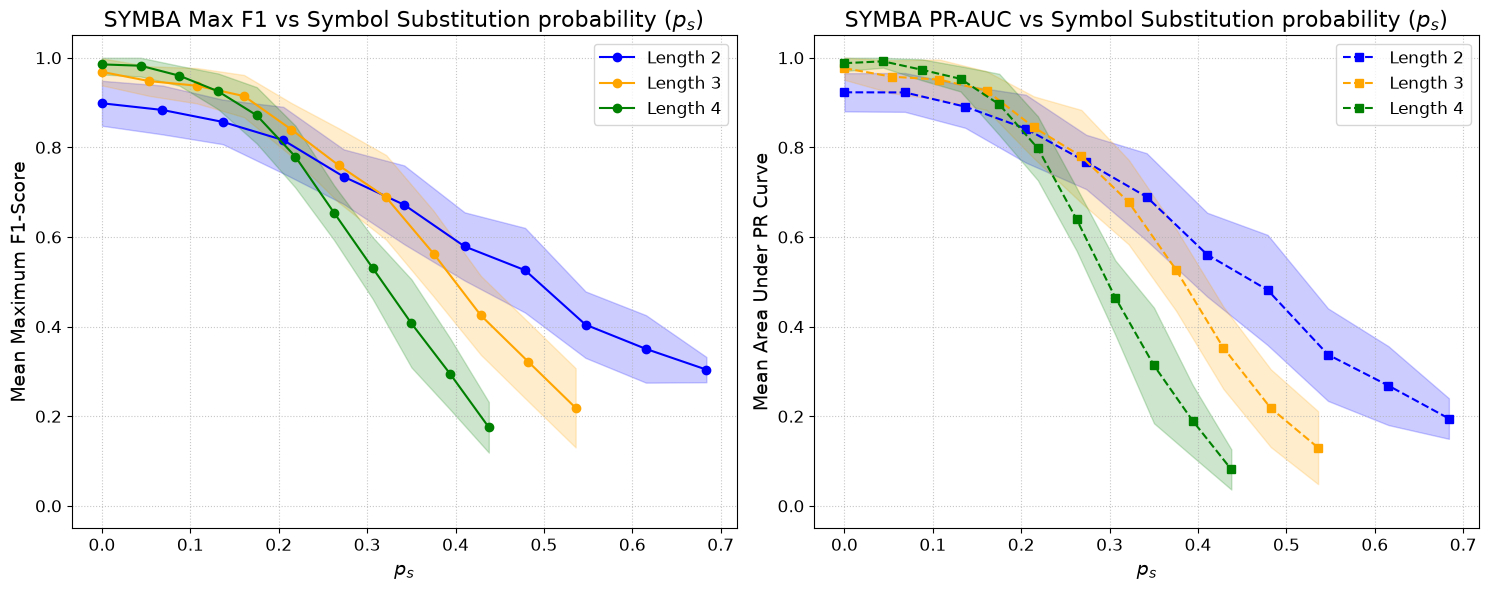

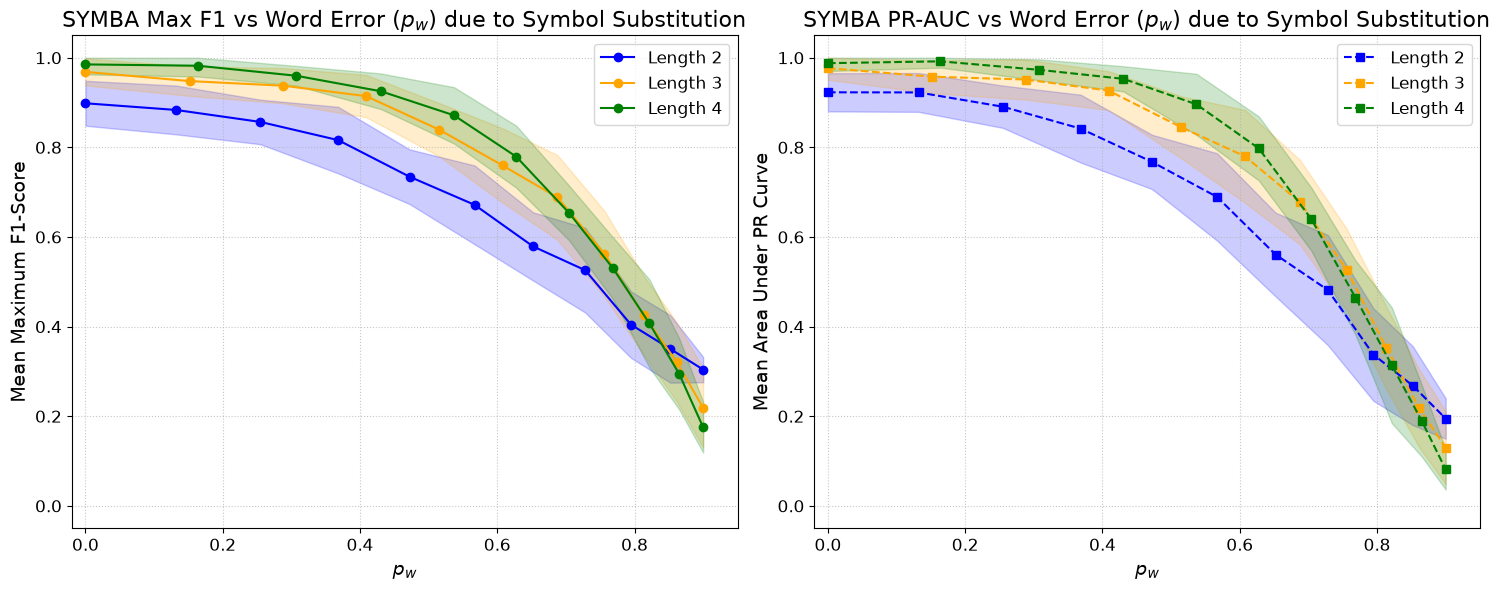

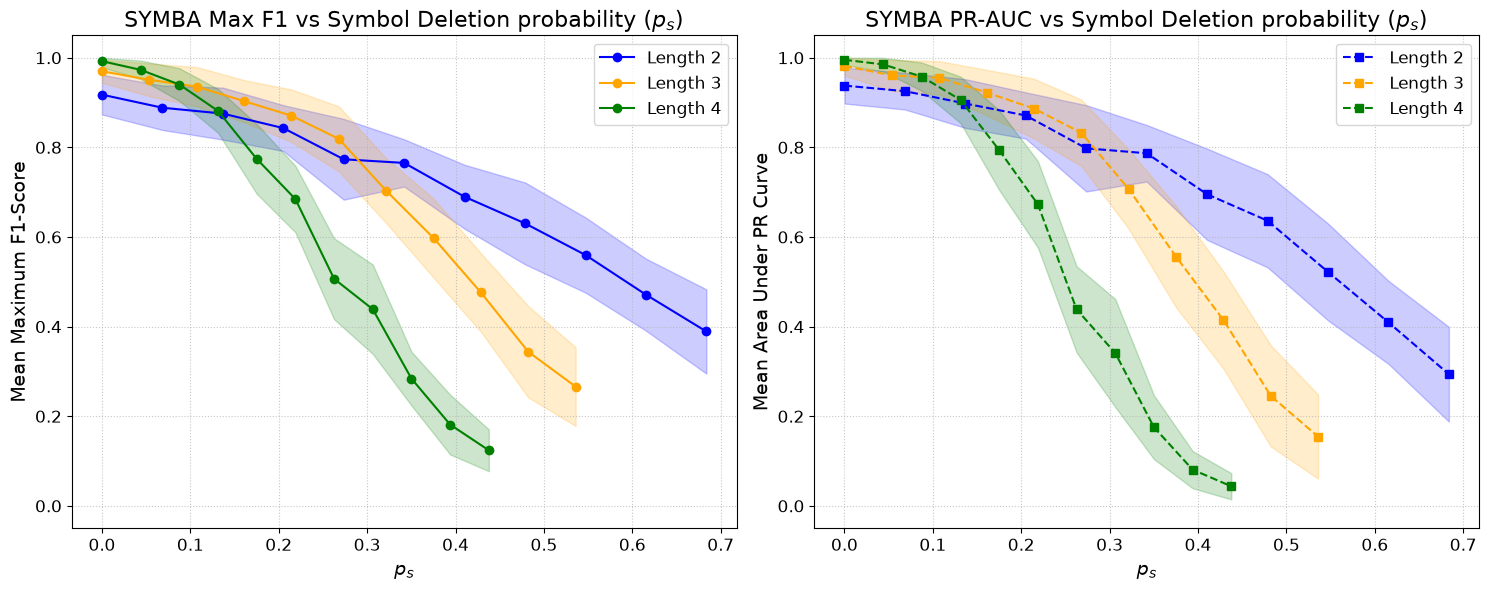

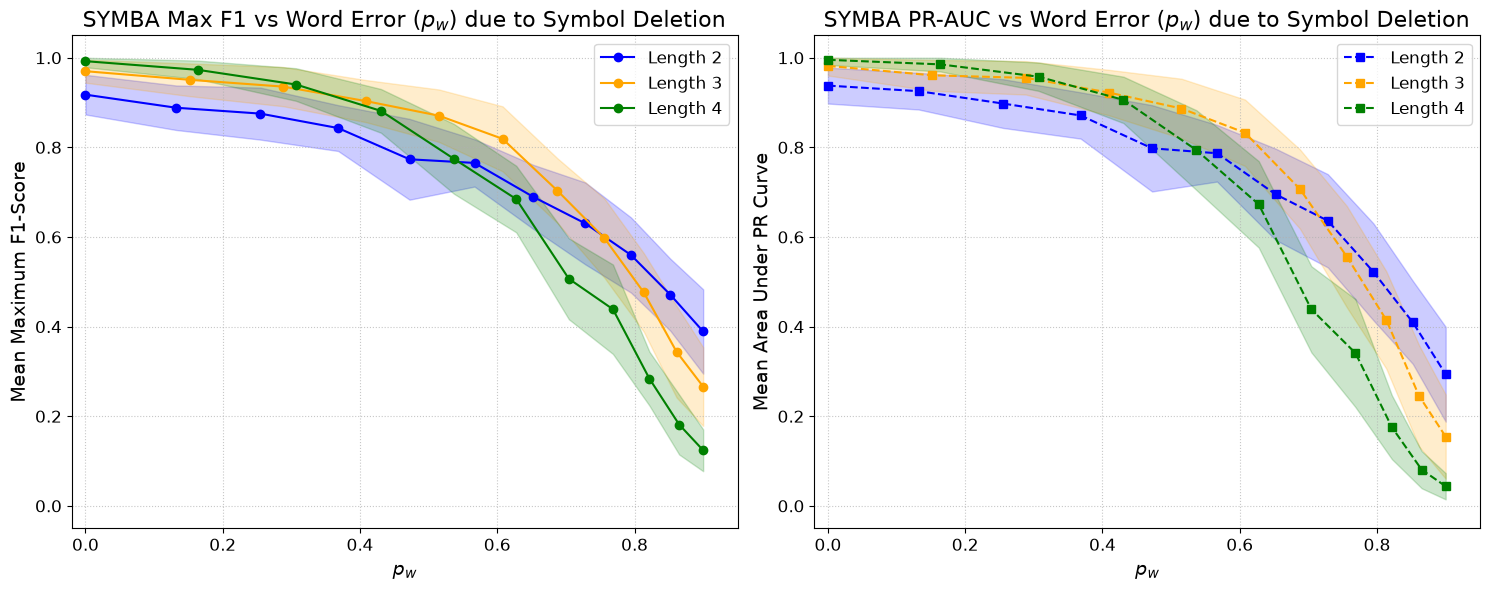

In [7]:
os.makedirs(FIG_DIR, exist_ok=True)
fig_suffix = f"alph{alph_length}_g{gamma}_n{num_words}_r{rep_words}_ord{ordered_words_noise}_nsr{nsr_fixed}.svg"

for noise_type in noise_types:
    plot_independent_symba_vs_ps(aggregated_results_dict[noise_type], noise_type=noise_type,
                                 save_fig=False, filename=f"{FIG_DIR}/symba_{noise_type}_vs_ps_{fig_suffix}")
    plot_independent_symba_vs_pw(aggregated_results_dict[noise_type], noise_type=noise_type,
                                 save_fig=False, filename=f"{FIG_DIR}/symba_{noise_type}_vs_pw_{fig_suffix}")


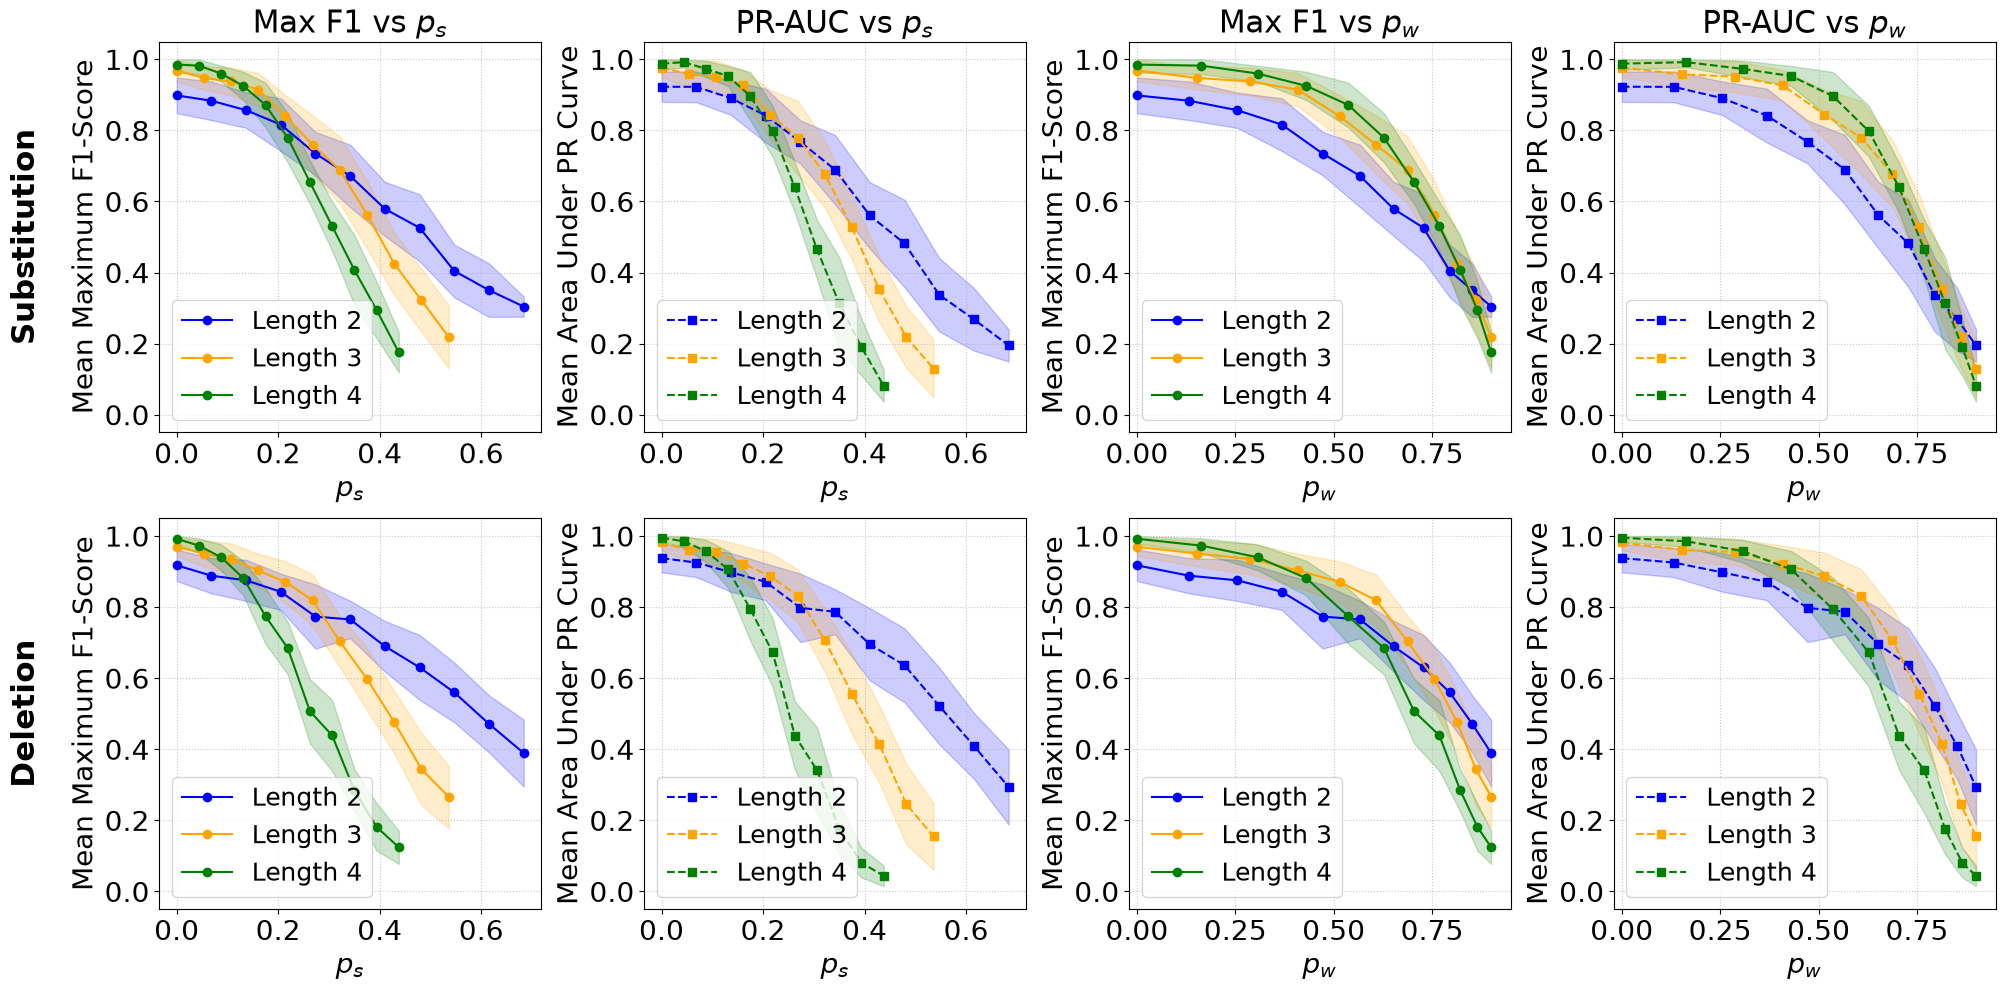

In [8]:
plot_symba_vs_ps_and_pw_combined(
    aggregated_results_dict,
    noise_types=noise_types,
    save_fig=False,
    filename=f"{FIG_DIR}/symba_substitution_deletion_combined_{fig_suffix}"
)


#### Convergence of the empirical observed probability in shuffled sequences to the analytical expected probability 

In [9]:
def add_length_to_original_dict(original):

    reorganized = defaultdict(lambda: defaultdict(dict))



    for param, tuple_dict in original.items():
        for tup, value in tuple_dict.items():
            length = len(tup)
            reorganized[param][length][tup] = value
    return reorganized

def multiple_shuffles_fixed_nsr_comparison(Bs=[10, 100], nsr=10, 
                                            ordered_words=0,
                                            alph_length=20, num_2words=10, num_3words=10, num_4words=10,
                                            rep_2words=10, rep_3words=10, rep_4words=10, gamma=1, 
                                            spacebar=1, space_weight=10, time_bin=2, max_size=4,
                                            positive_js=1, with_space=0, different_alphabet = 0
):
    # Storage
    hyper_seqs_per_nsr = {}
    mean_expected_analytical_withlength_nsr = {}
    mean_expected_shuffle_B = {}

    print(f"Generating data for NSR={nsr}")
    # === Generate synthetic data ONCE ===
    hyper_seq, spike_seq, _, _ = generate_synthetic_sequence(
                alph_length=alph_length, num_unique_2words=num_2words,
                num_unique_3words=num_3words, num_unique_4words=num_4words,
                rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words,
                nsr=nsr, gamma=gamma, spacebar=spacebar, space_weight=space_weight,
                ordered_words=ordered_words, time_bin=time_bin, different_alphabet=different_alphabet
            )


    hyper_seqs_per_nsr[nsr] = hyper_seq
    
    # Get Analytical Ground Truth
    _, expected_probs = symba.observed_counts_and_expected_probs(
        hyper_seq, spike_seq, max_size=max_size, ordered_words=ordered_words
    )
    
    mean_expected_analytical_withlength_nsr = add_length_to_original_dict({nsr: expected_probs})

    # === Perform Shuffles ===
    for random_shuffles in Bs:
        print(f"Running shuffles for B={random_shuffles}...")
        
        _, stats_shuffle = symba.compute_scores(
                    hyper_seq, size_max=max_size, B=random_shuffles, score_type="p_value", 
                    with_space=with_space, positive_score=positive_js, ordered_words=ordered_words
                )

        # Process and store
        mu_shuffle = {nsr: {kt: s['mu_null'] for kt, s in stats_shuffle.items()}}
        mean_expected_shuffle_B[random_shuffles] = add_length_to_original_dict(mu_shuffle)

    return hyper_seqs_per_nsr, mean_expected_analytical_withlength_nsr, mean_expected_shuffle_B

In [10]:
def compute_diffs_by_length_vs_B(mean_expected_analytical, mean_expected_shuffle_B, hyper_seq, abs_diff=True):
    """
    Compute motif differences for each B separately.
    Returns: {B: {(param, length): np.array of diffs}}
    """
    diffs_by_B = {}
    for B, shuffle_dict in mean_expected_shuffle_B.items():
        diffs_by_param_len = {}
        for param in mean_expected_analytical.keys():
            if param not in shuffle_dict:
                continue
            lengths = set(mean_expected_analytical[param].keys()) & set(shuffle_dict[param].keys())
            for l_val in lengths:
                motifs = set(mean_expected_analytical[param][l_val].keys()) | set(shuffle_dict[param][l_val].keys())
                diffs = []
                for motif in motifs:
                    v1 = mean_expected_analytical[param][l_val].get(motif, 0)
                    v2 = shuffle_dict[param][l_val].get(motif, 0)
                    # normalize v2 by sequence length
                    #if param in hyper_seq:
                    v2 /= (len(hyper_seq[param]) - l_val + 1)
                    diffs.append(np.abs(v1 - v2) if abs_diff else (v1 - v2))
                if diffs:
                    diffs_by_param_len[(param, l_val)] = np.array(diffs)
        diffs_by_B[B] = diffs_by_param_len
    return diffs_by_B

In [11]:
### Parameters of the shuffle-convergence experiment
alph_length = 10
num_2words = 20
num_3words = 20
num_4words = 20
rep_2words = 10
rep_3words = 5
rep_4words = 30
ordered_words = 0
gamma = 0.
spacebar = 0
space_weight = 10
time_bin = 2
max_size = 4

nsr_val = 30  # arbitrary choice for this example
Bs_to_test = [10, 30, 100, 300, 1000]

# 1. Run the generation and shuffles
symba.set_seed(SEED)
h_seqs, analytical, mean_expected_shuffle_B = multiple_shuffles_fixed_nsr_comparison(Bs=Bs_to_test, nsr=nsr_val,
                                            ordered_words=ordered_words,
                                            alph_length=alph_length, num_2words=num_2words,
                                            num_3words=num_3words, num_4words=num_4words,
                                            rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words,
                                            gamma=gamma,
                                            spacebar=spacebar, space_weight=space_weight, time_bin=time_bin, max_size=max_size,
                                            positive_js=1, with_space=0, different_alphabet = 0)

# 2. Compute differences vs analytical
diffs_analytic_shuffle = compute_diffs_by_length_vs_B(analytical, mean_expected_shuffle_B, h_seqs)


Generating data for NSR=30
60
54
num unique 2words 14 num unique 3words 20 num unique 4words 20
using no cutoff in the noise addition
non noisy symbols number (signal length):  2980
symbolic sequence total length:  92380
Running shuffles for B=10...
Running shuffles for B=30...
Running shuffles for B=100...
Running shuffles for B=300...
Running shuffles for B=1000...


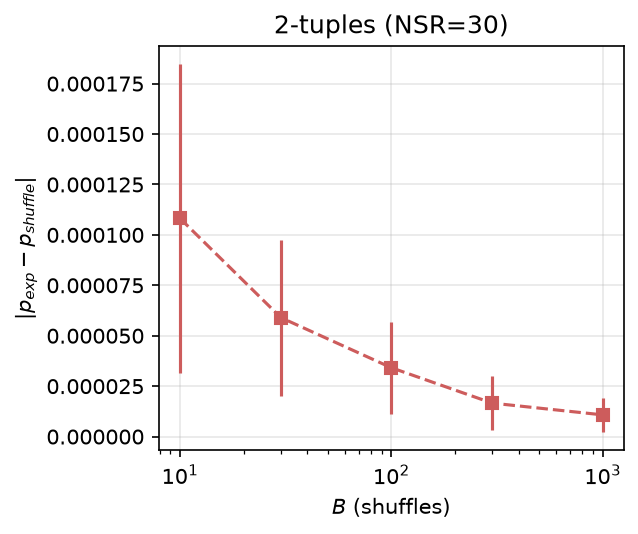

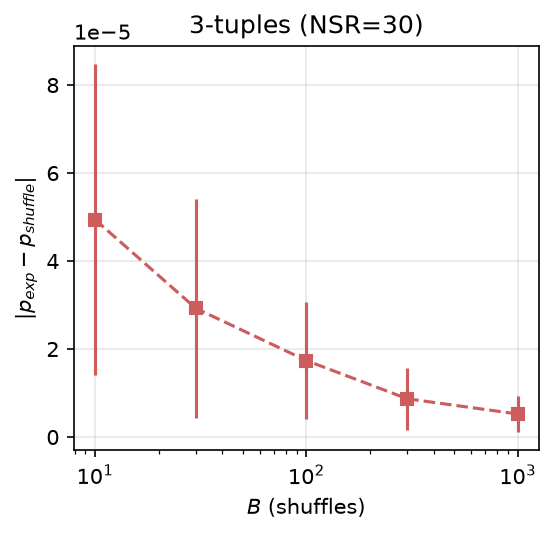

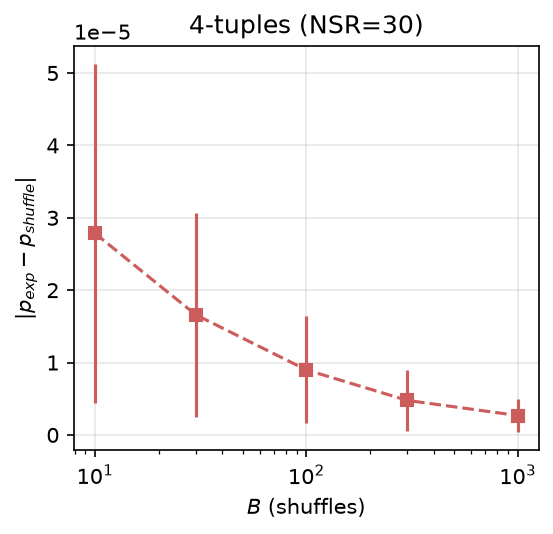

In [12]:
# 3. Plot
plot_diffs_analytic_shuffle(diffs_analytic_shuffle, alph_length=alph_length, gamma=gamma, save_fig = False,
                            output_dir=f"{FIG_DIR}/comparison_shuffle_analytic")

## Classification performance comparison SYMBA, vs shuffle (p-value and z-score) and batch (z-score)

In [13]:
### computing lower and upper NSR bounds (SM Sec. IV)
import math

rep_2words = 20
rep_3words = 20
rep_4words = 20

num_2words = 10
num_3words = 10
num_4words = 10

alph_length = 30
ordered_words = 1
#gamma = 0

#### the expressions below assume uniformly distributed noise symbols (gamma = 0)
# L_s: number of symbols in the signal (all planted copies of the motifs)
L_s = rep_2words * num_2words * 2 + rep_3words * num_3words * 3 + rep_4words * num_4words * 4
reps = {2: rep_2words, 3: rep_3words, 4: rep_4words}

lower_nsr, upper_nsr = {}, {}
for k in (2, 3, 4):
    m_k = reps[k]
    if ordered_words == 1:
        # data sparse below: the inner (k-2)-sub-tuple occurs by chance fewer times than the motif is repeated
        lower_nsr[k] = m_k * alph_length**(k - 2) / L_s if k >= 3 else 0.
        # noise dominated above: chance fluctuations (2 standard deviations) exceed the repetitions of the motif
        upper_nsr[k] = 0.25 * m_k**2 * alph_length**k / L_s
    else:
        # unordered motifs: a data-sparse regime exists only if the copies are few compared with
        # the k! orderings of the motif (each copy then acts as an ordered motif seen once)
        lower_nsr[k] = alph_length**(k - 2) / L_s if (k >= 3 and m_k <= math.factorial(k)) else 0.
        upper_nsr[k] = 0.25 * m_k**2 * unordered_count(alph_length, k) / L_s

print("ordered words case" if ordered_words == 1 else "unordered words case")
print("data sparse below:   " + ", ".join(f"lower_nsr{k} {lower_nsr[k]:g}" for k in (2, 3, 4)))
print("noise dominated above: " + ", ".join(f"upper_nsr{k} {upper_nsr[k]:g}" for k in (2, 3, 4)))


ordered words case
data sparse below:   lower_nsr2 0, lower_nsr3 0.333333, lower_nsr4 10
noise dominated above: upper_nsr2 50, upper_nsr3 1500, upper_nsr4 45000


### computing PR and ROC curves for the four methods: SYMBA, shuffle z-score and p-value and batch z-score

In [14]:
def evaluate_symba_vs_shuffle_across_nsr_full_curves(
    nsr_values, n_runs=5, number_random_shuffles=300, ordered_words=0, 
    alph_length=20, num_2words=10, num_3words=10, num_4words=10,
    rep_2words=10, rep_3words=10, rep_4words=10, gamma=1, 
    spacebar=1, space_weight=10, time_bin=2, max_size=4,
    positive_js=1, smooth_epsilon=1, measure='js_distance',
    quantiles_list=[0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                   0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99],
    with_space=0,
    exclude_subtuple_fp=True
):
    lengths = list(range(2, max_size + 1))
    methods = ['symba', 'shuffle_p', 'shuffle_z', 'batch_z']

    summary_data = {
        method: {length: {
            # per-run scalars, one list per NSR (each entry is a list of n_runs values)
            'runs_f1':        [], 'runs_auc_pr':  [], 'runs_auc_roc': [],
            'runs_precision': [], 'runs_recall':  [],
            # per-run full curves, one list per NSR (each entry is a list of n_runs arrays)
            'runs_precision_curve': [], 'runs_recall_curve': [],
            'runs_fpr_curve':       [], 'runs_tpr_curve':    [],
            'runs_y_true':          [], 'runs_y_scores':     [],
            # aggregated scalars
            'mean_f1':      [], 'std_f1':      [], 'sem_f1':      [],
            'mean_auc_pr':  [], 'std_auc_pr':  [], 'sem_auc_pr':  [],
            'mean_auc_roc': [], 'std_auc_roc': [], 'sem_auc_roc': [],
            'mean_precision': [], 'std_precision': [], 'sem_precision': [],
            'mean_recall':    [], 'std_recall':    [], 'sem_recall':    [],
        } for length in lengths}
        for method in methods
    }

    time_data = {
        'symba':   {'mean': [], 'std': [], 'runs': []},
        'shuffle': {'mean': [], 'std': [], 'runs': []},
        'seq_lengths': []
    }

    for nsr in nsr_values:
        print(f"Processing NSR = {nsr} (over {n_runs} runs)...")

        run_results = {
            method: {length: {
                'f1': [], 'auc_pr': [], 'auc_roc': [],
                'precision': [], 'recall': [],
                'precision_curve': [], 'recall_curve': [],
                'fpr_curve': [], 'tpr_curve': [],
                'y_true': [], 'y_scores': [],
            } for length in lengths}
            for method in methods
        }

        symba_times   = []
        shuffle_times = []
        run_seq_lengths = []

        for run in range(n_runs):
            hyper_seq, spike_seq, words_in_sentence_per_size_dict, _ = generate_synthetic_sequence(
                alph_length=alph_length, num_unique_2words=num_2words,
                num_unique_3words=num_3words, num_unique_4words=num_4words,
                rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words,
                nsr=nsr, gamma=gamma, spacebar=spacebar, space_weight=space_weight,
                ordered_words=ordered_words, time_bin=time_bin, different_alphabet=0
            )

            run_seq_lengths.append(len(hyper_seq))

            # === SYMBA — timed ===
            start_symba = time.perf_counter()
            observed_counts, mean_expected = symba.observed_counts_and_expected_probs(
                hyper_seq, spike_seq, max_size=max_size, ordered_words=ordered_words
            )
            js_dict = symba.js_score_per_size(
                hyper_seq, observed_counts, mean_expected,
                max_size=max_size, positive_js=positive_js,
                smooth_prior=smooth_epsilon,
                number_of_points=0,
                quantiles_list=quantiles_list, with_space=with_space, measure=measure
            )
            symba_times.append(time.perf_counter() - start_symba)

            # === SHUFFLE — timed ===
            start_shuffle = time.perf_counter()
            if number_random_shuffles > 0:
                _, results_all_k = symba.compute_scores(
                    hyper_seq, size_max=max_size, B=number_random_shuffles,
                    with_space=with_space, ordered_words=ordered_words,
                    shuffle_method='non_biased'
                )
            
                # included in timing — part of producing a usable score dict
                shuffle_p_dict_per_size = defaultdict(dict)
                shuffle_z_dict_per_size = defaultdict(dict)
                for motif, stats in results_all_k.items():
                    length = len(motif)
                    if with_space == 0 and -1 in motif:
                        continue
                    shuffle_p_dict_per_size[length][motif] = -np.log10(stats["p_enrich"])
                    shuffle_z_dict_per_size[length][motif] = stats["z"]
            
            shuffle_times.append(time.perf_counter() - start_shuffle)

            # === batch z-score ===
            batch_z_dict_per_size = symba.batch_zscores_per_size(
                hyper_seq, spike_seq, ordered_words=ordered_words, max_size=max_size,
                batch_num=20, positive_js=positive_js,
                observation_threshold=0, with_space=with_space
            )

            # === count tuples ===
            count2, count3, count4 = 0, 0, 0
            for word in observed_counts.keys():
                if len(word) == 2: count2 += 1
                if len(word) == 3: count3 += 1
                if len(word) == 4: count4 += 1

            # === collect all metrics including full curves ===
            def collect_metrics(score_dict, method_key):
                for length in lengths:
                    res = compute_pr_and_roc_subtuple_aware(
                        score_dict, words_in_sentence_per_size_dict, length,
                        count2, count3, count4,
                        ordered_words=ordered_words,
                        exclude_subtuple_fp=exclude_subtuple_fp,
                        observed_tuples=observed_counts.keys()
                    )
                    run_results[method_key][length]['f1'].append(res['best_f1'])
                    run_results[method_key][length]['auc_pr'].append(res['auc_pr'])
                    run_results[method_key][length]['auc_roc'].append(res['auc_roc'])
                    run_results[method_key][length]['precision'].append(res['best_precision'])
                    run_results[method_key][length]['recall'].append(res['best_recall'])
                    run_results[method_key][length]['precision_curve'].append(res['precision_curve'])
                    run_results[method_key][length]['recall_curve'].append(res['recall_curve'])
                    run_results[method_key][length]['fpr_curve'].append(res['fpr_curve'])
                    run_results[method_key][length]['tpr_curve'].append(res['tpr_curve'])
                    run_results[method_key][length]['y_true'].append(res['y_true'])
                    run_results[method_key][length]['y_scores'].append(res['y_scores'])

            collect_metrics(js_dict, 'symba')
            if number_random_shuffles > 0:
                collect_metrics(shuffle_p_dict_per_size, 'shuffle_p')
                collect_metrics(shuffle_z_dict_per_size, 'shuffle_z')
            collect_metrics(batch_z_dict_per_size, 'batch_z')

        # === Aggregate performance metrics ===
        for method in methods:
            for length in lengths:
                r = run_results[method][length]
                n = len(r['f1'])

                # per-run scalars (one list entry per NSR, containing n_runs values)
                summary_data[method][length]['runs_f1'].append(list(r['f1']))
                summary_data[method][length]['runs_auc_pr'].append(list(r['auc_pr']))
                summary_data[method][length]['runs_auc_roc'].append(list(r['auc_roc']))
                summary_data[method][length]['runs_precision'].append(list(r['precision']))
                summary_data[method][length]['runs_recall'].append(list(r['recall']))

                # per-run full curves (one list entry per NSR, containing n_runs arrays)
                summary_data[method][length]['runs_precision_curve'].append(r['precision_curve'])
                summary_data[method][length]['runs_recall_curve'].append(r['recall_curve'])
                summary_data[method][length]['runs_fpr_curve'].append(r['fpr_curve'])
                summary_data[method][length]['runs_tpr_curve'].append(r['tpr_curve'])
                summary_data[method][length]['runs_y_true'].append(r['y_true'])
                summary_data[method][length]['runs_y_scores'].append(r['y_scores'])

                # aggregated scalars
                for metric, values in [
                    ('f1',        r['f1']),
                    ('auc_pr',    r['auc_pr']),
                    ('auc_roc',   r['auc_roc']),
                    ('precision', r['precision']),
                    ('recall',    r['recall']),
                ]:
                    arr = np.array(values)
                    summary_data[method][length][f'mean_{metric}'].append(np.mean(arr))
                    summary_data[method][length][f'std_{metric}'].append(np.std(arr))
                    summary_data[method][length][f'sem_{metric}'].append(np.std(arr) / np.sqrt(n))

        # === Aggregate timing ===
        time_data['symba']['runs'].append(list(symba_times))
        time_data['symba']['mean'].append(np.mean(symba_times))
        time_data['symba']['std'].append(np.std(symba_times))
        time_data['shuffle']['runs'].append(list(shuffle_times))
        time_data['shuffle']['mean'].append(np.mean(shuffle_times))
        time_data['shuffle']['std'].append(np.std(shuffle_times))
        time_data['seq_lengths'].append(np.mean(run_seq_lengths))

    summary_data['n_runs'] = n_runs
    summary_data['nsr_values'] = list(nsr_values)
    time_data['nsr_values'] = list(nsr_values)
    return summary_data, time_data

In [15]:
### Parameters of the four-method comparison (main-text figure)
# Supplementary variants (only length-3 motifs): set num_2words = rep_2words = num_4words = rep_4words = 0,
# rep_3words = 10 or 5 and n_runs = 50; summaries of those runs are shipped too.
nsr_values = [1, 3, 10, 30, 100, 300]

max_size = 4
alph_length = 30
ordered_words = 1
gamma = 1.
num_2words = 20
num_3words = 20
num_4words = 20
rep_2words = 10
rep_3words = 10
rep_4words = 10

n_runs = 20
number_random_shuffles = 1000
quantiles_ls=[0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                   0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

RECOMPUTE_FOUR_METHODS = RECOMPUTE  # True: rerun the comparison (several hours); False: use the shipped summary

param_str = (
    f"_alph{alph_length}"
    f"_2w{num_2words}x{rep_2words}"
    f"_3w{num_3words}x{rep_3words}"
    f"_4w{num_4words}x{rep_4words}"
    f"_gamma{gamma}"
    f"_ord{ordered_words}"
    f"_nruns{n_runs}"
    f"_B{number_random_shuffles}"
)
full_results_path = f"data/complete_results_four_methods_faster_rns_1_300_{param_str}.pkl"  # hundreds of MB, not shipped
summary_path      = f"data/four_methods_summary{param_str}.pkl"                               # small, shipped

if RECOMPUTE_FOUR_METHODS:
    symba.set_seed(SEED)
    summary_data, time_data =  evaluate_symba_vs_shuffle_across_nsr_full_curves(
        nsr_values, n_runs=n_runs, number_random_shuffles=number_random_shuffles, ordered_words=ordered_words,
        alph_length=alph_length, num_2words=num_2words, num_3words=num_3words, num_4words=num_4words,
        rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words, gamma=gamma,
        spacebar=0, space_weight=10, time_bin=2, max_size=max_size,
        positive_js=1, smooth_epsilon=1, measure='js_distance',
        quantiles_list=quantiles_ls, with_space=0, exclude_subtuple_fp=True
    )


In [16]:
# Save a new run: the complete results (not shipped) and the small summary used by the figures below
if RECOMPUTE_FOUR_METHODS:
    os.makedirs("data", exist_ok=True)
    with open(full_results_path, "wb") as f:
        pickle.dump({'summary_data': summary_data, 'time_data': time_data}, f)
    with open(summary_path, "wb") as f:
        pickle.dump({'summary_data': slim_summary_data(summary_data), 'time_data': time_data}, f)
    print(f"Saved: {full_results_path}\nSaved: {summary_path}")


In [17]:
### Load the summary (the shipped one, or the one just saved)
with open(summary_path, "rb") as f:
    loaded = pickle.load(f)

summary_data = loaded['summary_data']
time_data    = loaded['time_data']


Plot saved as: outputs/figures/four_methods_AUC_maxF1_nsr_linear_alph30_2w20x10_3w20x10_4w20x10_gamma1.0_ord1n_runs20.svg


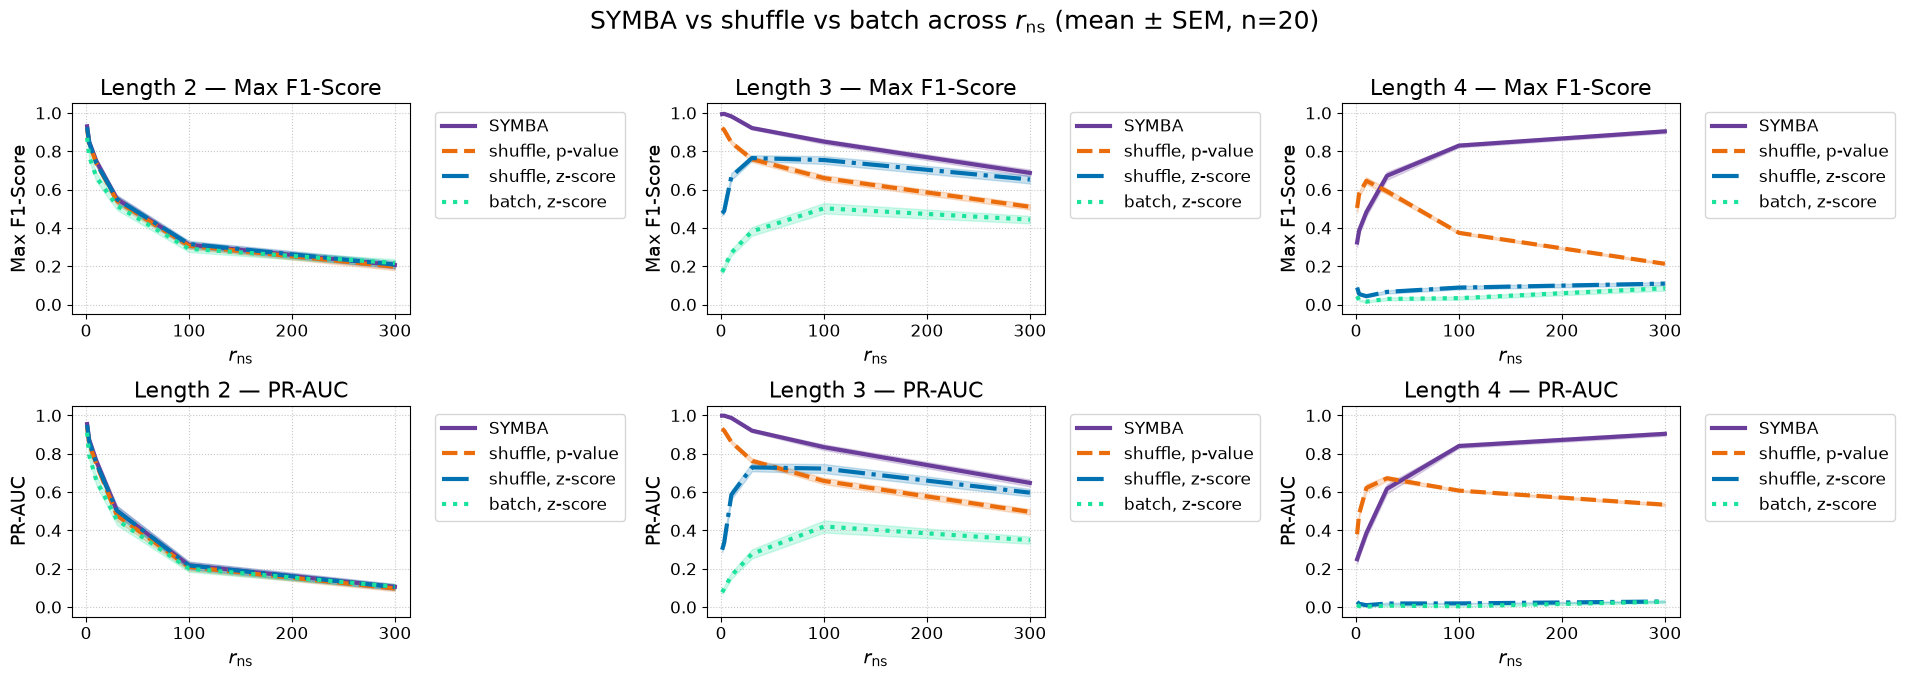

In [18]:
filename = (
    f"{FIG_DIR}/four_methods_AUC_maxF1_nsr_linear"
    f"_alph{alph_length}"
    f"_2w{num_2words}x{rep_2words}"
    f"_3w{num_3words}x{rep_3words}"
    f"_4w{num_4words}x{rep_4words}"
    f"_gamma{gamma}"
    f"_ord{ordered_words}"
    f"n_runs{n_runs}"
    f".svg"
)

### F1 and PR-AUC only
plot_summary_across_nsr_four_methods(
    summary_data, lengths=[2, 3, 4], save_fig=True, filename=filename,
    metrics=('f1', 'auc_pr'), figsize = (6.4, 3.3),
    metric_labels=('Max F1-Score', 'PR-AUC'),
)

### all five scalar metrics
#plot_summary_across_nsr_four_methods(
#    summary_data, lengths=[2, 3, 4],
#    metrics=('f1', 'auc_pr', 'auc_roc', 'precision', 'recall'),
#    metric_labels=('Max F1-Score', 'PR-AUC', 'ROC-AUC', 'Precision @ best F1', 'Recall @ best F1'),
#)

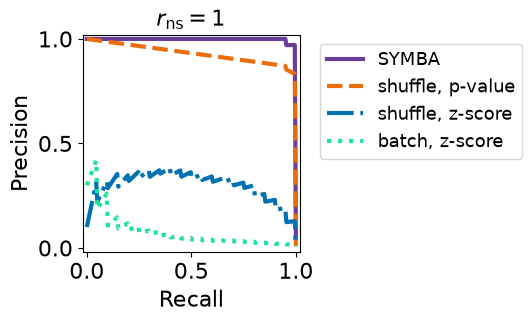

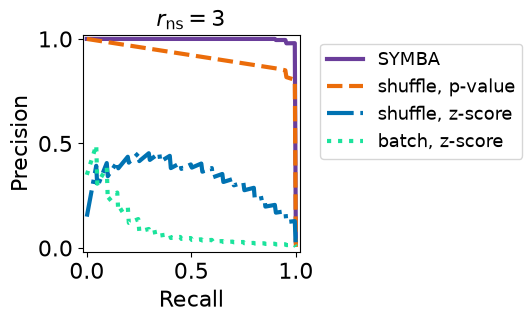

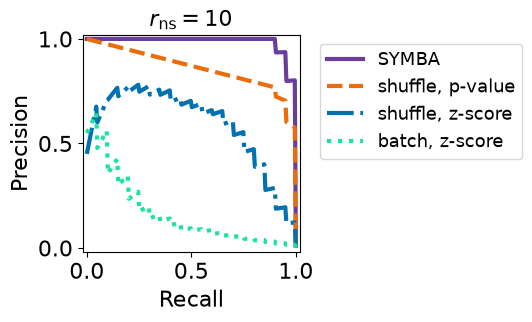

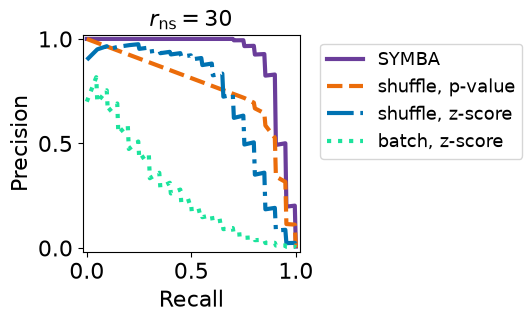

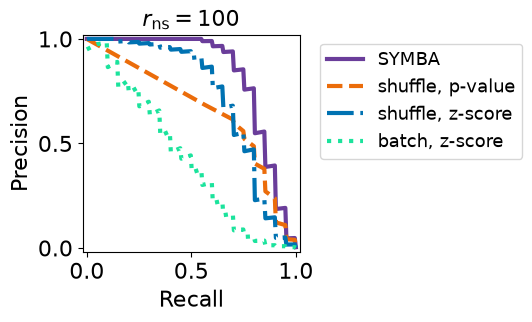

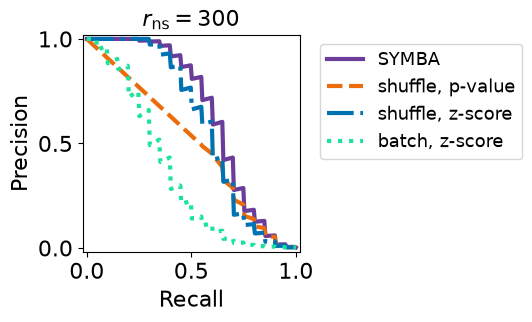

In [19]:
plot_roc_or_pr_curves_from_summary(
    summary_data,
    curve_type="pr",
    show_sem=False,
    show_lengths=[3],
    figsize=(5.5, 5.5),
    legend_loc='outside', 
    save_fig=False,
    save_dir=f"{FIG_DIR}/roc_pr_curves",
    alph_length=alph_length, num_2words=num_2words, num_3words=num_3words, num_4words=num_4words,
    rep_2words=rep_2words, rep_3words=rep_3words, rep_4words=rep_4words,
    gamma=gamma, ordered_words=ordered_words
)


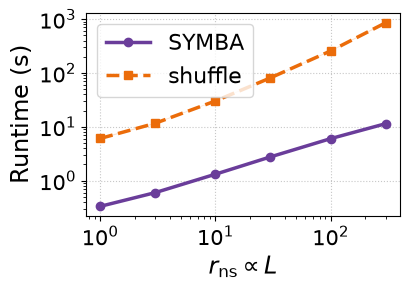

In [20]:
# Format filename
base_file = (
    f"methods_runtime"
    f"_alph{alph_length}"
    f"_2w{num_2words}x{rep_2words}"
    f"_3w{num_3words}x{rep_3words}"
    f"_4w{num_4words}x{rep_4words}"
    f"_gamma{gamma}"
    f"_ord{ordered_words}"
    f"n_runs{n_runs}"
    f".svg"
    )
filename_out = os.path.join(FIG_DIR, base_file)

# Plot and save
plot_runtime_scaling(
    time_data=time_data,
    #nsr_values=nsr_sweep,  
    figsize=(4.2,3),
    nsr_values=time_data['nsr_values'], 
    log_y=True, 
    save_fig=True, 
    filename=filename_out
) 

#### Counting baseline and detections at fixed significance thresholds
Analyses reported in the SM (comparison between the p-value and the z-score of the shuffle method), in the setting of the four-method comparison above: the counting baseline for ordered 4-tuples, and the planted motifs and other tuples detected at the threshold used in the paper (SYMBA) and at the conventional and corrected thresholds of the p-value.

In [ ]:
### Counting baseline (SM, table comparing SYMBA, the shuffle p-value and z-score, and counting for ordered 4-tuples)
# Counting ranks the tuples by their number of occurrences. It is evaluated as the other methods
# (sub-tuples of longer planted motifs are not counted as false positives), on 20 new realizations
# with the parameters of the four-method comparison above (no shuffles: about 30 s).
import io

counting_runs = {k: {"f1": [], "auc_pr": []} for k in range(2, max_size + 1)}
for nsr in nsr_values:
    f1_runs = {k: [] for k in counting_runs}
    auc_runs = {k: [] for k in counting_runs}
    for run in range(n_runs):
        symba.set_seed(7000 + 100 * nsr + run)  # seeds of the realizations reported in the SM
        with contextlib.redirect_stdout(io.StringIO()):
            hyper_seq, spike_seq, motifs_per_size, _ = generate_synthetic_sequence(
                alph_length=alph_length, num_unique_2words=num_2words, num_unique_3words=num_3words,
                num_unique_4words=num_4words, rep_2words=rep_2words, rep_3words=rep_3words,
                rep_4words=rep_4words, nsr=nsr, gamma=gamma, spacebar=0, space_weight=10,
                ordered_words=ordered_words, time_bin=2, different_alphabet=0)
            observed_counts, _ = observed_counts_and_expected_probs(
                hyper_seq, spike_seq, max_size=max_size, ordered_words=ordered_words)
        # the score of a tuple is its number of occurrences
        count_scores = {k: {t: c for t, c in observed_counts.items() if len(t) == k and -1 not in t}
                        for k in counting_runs}
        n_tuples = {k: sum(1 for t in observed_counts if len(t) == k) for k in (2, 3, 4)}
        for k in counting_runs:
            res = compute_pr_and_roc_subtuple_aware(
                count_scores, motifs_per_size, k, n_tuples[2], n_tuples[3], n_tuples[4],
                ordered_words=ordered_words, exclude_subtuple_fp=True,
                observed_tuples=observed_counts.keys())
            f1_runs[k].append(res["best_f1"])
            auc_runs[k].append(res["auc_pr"])
    for k in counting_runs:
        counting_runs[k]["f1"].append(np.mean(f1_runs[k]))
        counting_runs[k]["auc_pr"].append(np.mean(auc_runs[k]))
    print(f"rns = {nsr} done")

# maximum F1 score / PR-AUC for ordered 4-tuples, mean over the runs
k = 4
print(f"{'ordered 4-tuples':18s}" + "".join(f"rns={x:<11}" for x in nsr_values))
for name, f1, auc_pr in [
    ("SYMBA",             summary_data['symba'][k]['mean_f1'],     summary_data['symba'][k]['mean_auc_pr']),
    ("shuffle, p-value",  summary_data['shuffle_p'][k]['mean_f1'], summary_data['shuffle_p'][k]['mean_auc_pr']),
    ("shuffle, z-score",  summary_data['shuffle_z'][k]['mean_f1'], summary_data['shuffle_z'][k]['mean_auc_pr']),
    ("counting",          counting_runs[k]['f1'],                  counting_runs[k]['auc_pr']),
]:
    print(f"{name:18s}" + "".join(f"{a:.2f} / {b:.2f}  " for a, b in zip(f1, auc_pr)))


rns = 1 done
rns = 3 done
rns = 10 done
rns = 30 done
rns = 100 done
rns = 300 done
ordered 4-tuples  rns=1          rns=3          rns=10         rns=30         rns=100        rns=300        
SYMBA             0.32 / 0.25  0.39 / 0.28  0.48 / 0.39  0.67 / 0.62  0.83 / 0.84  0.90 / 0.90  
shuffle, p-value  0.50 / 0.38  0.58 / 0.49  0.65 / 0.62  0.59 / 0.67  0.37 / 0.61  0.21 / 0.53  
shuffle, z-score  0.09 / 0.03  0.05 / 0.02  0.04 / 0.01  0.07 / 0.02  0.09 / 0.02  0.11 / 0.03  
counting          1.00 / 1.00  0.95 / 0.49  0.46 / 0.15  0.10 / 0.03  0.02 / 0.00  0.00 / 0.00  


In [ ]:
### Detections at fixed significance thresholds (SM, discussion of significance thresholds and multiple testing)
# Planted motifs (TP) and other tuples (FP) detected per sequence by SYMBA (BJS > 0.6) and by the shuffle
# p-value: p < 0.05, Bonferroni and Benjamini-Hochberg corrections at 5%. Sub-tuples of longer planted motifs
# are excluded, as in the PR curves. Computed from the per-tuple scores in the complete results (not shipped);
# the small result is shipped in data/.
thresholds_path = f"data/four_methods_thresholded{param_str}.pkl"
RECOMPUTE_THRESHOLDED = RECOMPUTE  # True: recompute from the complete results; False: use the shipped result

def detections_at_thresholds(full_summary, lengths=(2, 3, 4), bjs_threshold=0.6, alpha=0.05):
    out = {}
    for k in lengths:
        out[k] = {name: {"tp": [], "fp": []} for name in ("symba", "p_005", "bonferroni", "bh")}
        for i in range(len(full_summary["nsr_values"])):
            runs = {name: {"tp": [], "fp": []} for name in out[k]}
            for y_true, y_scores in zip(full_summary["symba"][k]["runs_y_true"][i],
                                        full_summary["symba"][k]["runs_y_scores"][i]):
                detected = y_scores > bjs_threshold
                runs["symba"]["tp"].append(np.sum(detected & (y_true == 1)))
                runs["symba"]["fp"].append(np.sum(detected & (y_true == 0)))
            for y_true, y_scores in zip(full_summary["shuffle_p"][k]["runs_y_true"][i],
                                        full_summary["shuffle_p"][k]["runs_y_scores"][i]):
                p = np.minimum(10.0 ** (-y_scores), 1.0)  # scores are -log10(p)
                n_tests = len(p)
                order = np.argsort(p)
                below = np.where(p[order] <= alpha * np.arange(1, n_tests + 1) / n_tests)[0]
                bh = np.zeros(n_tests, dtype=bool)
                if len(below):
                    bh[order[:below[-1] + 1]] = True
                for name, detected in [("p_005", p < alpha), ("bonferroni", p <= alpha / n_tests), ("bh", bh)]:
                    runs[name]["tp"].append(np.sum(detected & (y_true == 1)))
                    runs[name]["fp"].append(np.sum(detected & (y_true == 0)))
            for name in out[k]:
                out[k][name]["tp"].append(np.mean(runs[name]["tp"]))
                out[k][name]["fp"].append(np.mean(runs[name]["fp"]))
            out[k]["symba"].setdefault("fp_max", []).append(int(np.max(runs["symba"]["fp"])))
    return out

if RECOMPUTE_THRESHOLDED or not os.path.exists(thresholds_path):
    with open(full_results_path, "rb") as f:  # several hundred MB
        full_summary = pickle.load(f)["summary_data"]
    detections = detections_at_thresholds(full_summary)
    del full_summary
    with open(thresholds_path, "wb") as f:
        pickle.dump({"nsr_values": list(nsr_values), "n_runs": n_runs, "detections": detections}, f)
    print(f"Saved: {thresholds_path}")

with open(thresholds_path, "rb") as f:
    detections = pickle.load(f)["detections"]

# mean TP / FP per sequence (20 planted motifs of each length)
for k in (2, 3, 4):
    print(f"\n{k}-tuples: TP / FP per sequence")
    print(f"{'rns':>5}  {'SYMBA > 0.6':>16}  {'p < 0.05':>16}  {'Bonferroni':>12}  {'BH':>12}")
    for i, x in enumerate(nsr_values):
        d = detections[k]
        print(f"{x:>5}  {d['symba']['tp'][i]:6.1f} / {d['symba']['fp'][i]:5.2f}  "
              f"{d['p_005']['tp'][i]:6.1f} / {d['p_005']['fp'][i]:7.1f}  "
              f"{d['bonferroni']['tp'][i]:4.1f} / {d['bonferroni']['fp'][i]:4.1f}  "
              f"{d['bh']['tp'][i]:4.1f} / {d['bh']['fp'][i]:4.1f}")
    print(f"  SYMBA, maximum FP in a single sequence: {max(detections[k]['symba']['fp_max'])}")



2-tuples: TP / FP per sequence
  rns       SYMBA > 0.6          p < 0.05    Bonferroni            BH
    1     8.0 /  0.10    19.1 /     7.1   0.0 /  0.0  10.8 /  0.4
    3     6.0 /  0.00    17.0 /    10.2   0.0 /  0.0   2.6 /  0.3
   10     3.4 /  0.00    15.0 /    12.2   0.0 /  0.0   0.0 /  0.0
   30     1.7 /  0.00    11.2 /    19.5   0.0 /  0.0   0.0 /  0.0
  100     0.4 /  0.00     5.8 /    26.6   0.0 /  0.0   0.0 /  0.0
  300     0.1 /  0.05     3.8 /    30.2   0.0 /  0.0   0.0 /  0.0
  SYMBA, maximum FP in a single sequence: 1

3-tuples: TP / FP per sequence
  rns       SYMBA > 0.6          p < 0.05    Bonferroni            BH
    1    15.4 /  0.00    20.0 /   264.1   0.0 /  0.0   0.0 /  0.0
    3    16.2 /  0.00    20.0 /   359.7   0.0 /  0.0   0.0 /  0.0
   10    17.5 /  0.00    20.0 /   463.4   0.0 /  0.0   0.0 /  0.0
   30    15.6 /  0.10    19.6 /   566.2   0.0 /  0.0   0.0 /  0.0
  100    13.2 /  0.05    18.9 /   736.8   0.0 /  0.0   0.0 /  0.0
  300     9.6 /  0.45    1

### Choosing the BJS threshold from shuffled sequences
For each tuple length $k$, the sequence is shuffled preserving the counts of all $(k-1)$-tuples (as in the shuffle method), so that the shuffled sequences satisfy the null model of SYMBA and any high score in them is a false positive (SM, section on the choice of the threshold). Two choices of the threshold:
- `bjs_threshold_percentile`: the 95th percentile of the maximum score of the $k$-tuples in each shuffled sequence (conservative: about 5% probability of even one false positive);
- `bjs_threshold_fdr`: the smallest threshold for which the false positives are expected to be at most 5% of the detected tuples (false discovery rate; detects more motifs, at the cost of a few false positives).

About ten shuffled sequences are enough. Both functions can reuse the same shuffled sequences (`shuffled_js_scores`).

In [ ]:
### BJS threshold of each tuple length from shuffled sequences, on one synthetic sequence
# Same parameters as the four-method comparison above, at rns = 10 (takes about 20 s)
import io

alph_length = 30
max_size = 4
ordered_words = 1
n_shuffles = 10

symba.set_seed(SEED)
with contextlib.redirect_stdout(io.StringIO()):
    hyper_seq, spike_seq, motifs_per_size, _ = generate_synthetic_sequence(
        alph_length=alph_length, num_unique_2words=20, num_unique_3words=20, num_unique_4words=20,
        rep_2words=10, rep_3words=10, rep_4words=10, nsr=10, gamma=1., spacebar=0, space_weight=10,
        ordered_words=ordered_words, time_bin=2, different_alphabet=0)
    observed_counts, expected_probs = observed_counts_and_expected_probs(
        hyper_seq, spike_seq, max_size=max_size, ordered_words=ordered_words)
    js_per_size = js_score_per_size(hyper_seq, observed_counts, expected_probs, max_size=max_size, positive_js=1,
                                    smooth_prior=1, number_of_points=0)

# the same shuffled sequences are used for both thresholds
shuffled_scores = shuffled_js_scores(hyper_seq, max_size=max_size, n_shuffles=n_shuffles, ordered_words=ordered_words)
thr_percentile = bjs_threshold_percentile(hyper_seq, max_size=max_size, shuffled_scores=shuffled_scores)
thr_fdr = bjs_threshold_fdr(js_per_size, hyper_seq, max_size=max_size, ordered_words=ordered_words,
                            shuffled_scores=shuffled_scores)

# tuples above the threshold include the sub-tuples of longer planted motifs (real dependencies)
for k in range(2, max_size + 1):
    planted = set(map(tuple, motifs_per_size[k]))
    for name, thr in [("95th percentile", thr_percentile[k]), ("FDR 5%", thr_fdr[k]), ("fixed 0.6", 0.6)]:
        n_above = sum(score > thr for score in js_per_size[k].values())
        n_planted = sum(js_per_size[k].get(motif, 0) > thr for motif in planted)
        print(f"k = {k}, {name:15s}: threshold {thr:.2f}, {n_above:3d} tuples above it, "
              f"{n_planted} of {len(planted)} planted motifs")


k = 2, 95th percentile: threshold 0.54,  36 tuples above it, 11 of 20 planted motifs
k = 2, FDR 5%         : threshold 0.43,  73 tuples above it, 14 of 20 planted motifs
k = 2, fixed 0.6      : threshold 0.60,  20 tuples above it, 6 of 20 planted motifs
k = 3, 95th percentile: threshold 0.56,  58 tuples above it, 19 of 20 planted motifs
k = 3, FDR 5%         : threshold 0.46,  61 tuples above it, 19 of 20 planted motifs
k = 3, fixed 0.6      : threshold 0.60,  56 tuples above it, 18 of 20 planted motifs
k = 4, 95th percentile: threshold 0.50,   2 tuples above it, 2 of 20 planted motifs
k = 4, FDR 5%         : threshold 0.49,   2 tuples above it, 2 of 20 planted motifs
k = 4, fixed 0.6      : threshold 0.60,   1 tuples above it, 1 of 20 planted motifs


### Markov generated sequences

In [21]:
tuple_length = 3

mc = HigherOrderMarkov(
    alphabet_size=20,
    order=tuple_length - 2,
    alpha=1, 
    seed=1
)

#seq = mc.sample(1000)

dataset_seqs = mc.sample_dataset(10, 5100)

In [22]:
smooth_epsilon = 1
max_size = 4
positive_js = 1
ordered_words = 1
quantiles_list1 = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                   0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

hyper_symbolic_sequence = dataset_seqs[0]
spike_symbolic_sequence = [pos for pos in range(len(hyper_symbolic_sequence))]

observed_counts, expected_probs = symba.observed_counts_and_expected_probs(hyper_symbolic_sequence, spike_symbolic_sequence, max_size=max_size, 
                                                                     ordered_words = ordered_words)

js_per_size_dict = symba.js_score_per_size(
            hyper_symbolic_sequence, observed_counts, expected_probs, 
            max_size = max_size, positive_js = positive_js,
            smooth_prior = smooth_epsilon,
            number_of_points=0,
            quantiles_list=quantiles_list1, with_space=0,
            measure = "js_distance"
                )

Total expected probability for size  1 :  0.9999999999999998
Total expected probability for size  2 :  0.9297901191849288
Total expected probability for size  3 :  0.7419799905866804
Total expected probability for size  4 :  0.359502082966382


count_sign_thr 43


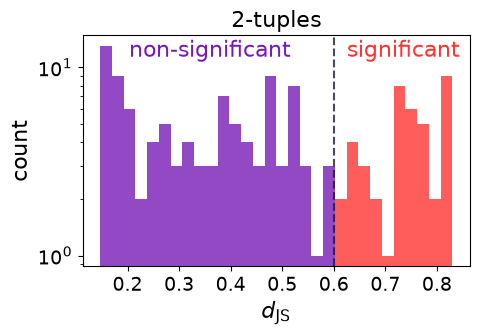

count_sign_thr 0


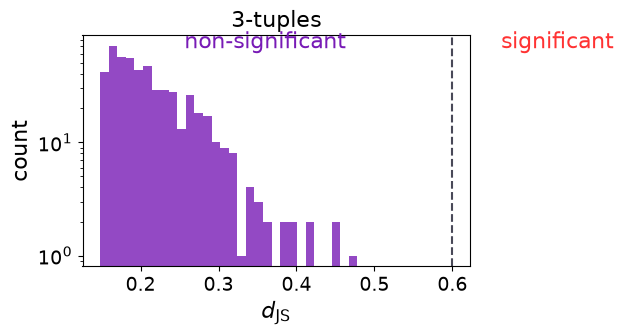

count_sign_thr 0


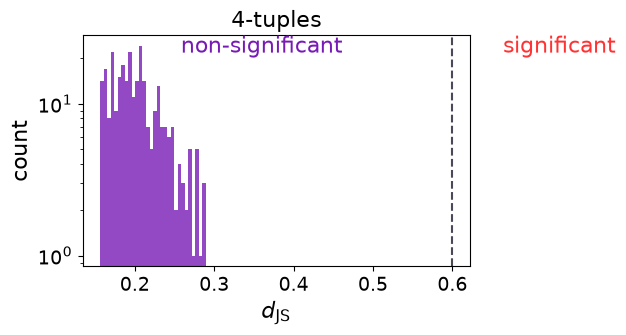

In [23]:
labels = {2: '2-tuples', 3: '3-tuples', 4: '4-tuples'}
for hyper_size, scores in js_per_size_dict.items():
    plot_score_histogram(scores, threshold=0.6, title=labels[hyper_size], ylabel="count")


In [24]:
tuple_length = 4
alph_length = 20

p_s = 0.1  # symbol substitution probability
threshold = 0.5  # set your threshold here for statistical significance of a tuple

In [25]:
mc = HigherOrderMarkov(
    alphabet_size=alph_length,
    order=tuple_length - 2,
    alpha=1, 
    seed=1
)

#seq = mc.sample(1000)

dataset_seqs = mc.sample_dataset(10, 5100)

##### number of motifs above the threshold for different probability of symbol error

In [26]:
#### generating the set of symbolic sequences 

tuple_length = 3 #### the tuple length for which p_exp should hold true (generated by a Markov process of order tuple_length-2)
                 #### we expect none or very few tuples of length tuple_length to be significant, since the Markov process generates them with the expected probability distribution.
                 #### for tuples of length < tuple_length we instead expect many tuples to be significant, since they are generated with a probability distribution that is not the expected one.
alph_length = 20

mc = HigherOrderMarkov(
    alphabet_size=alph_length,
    order=tuple_length - 2,
    alpha=1, 
    seed=1
)

#seq = mc.sample(1000)
sequence_length = 100100

dataset_seqs = mc.sample_dataset(5, sequence_length)

#### looping over all tuple_length and noise type at once and saving results as a unique file for a given alphabet length

In [27]:
import pickle
import os
import numpy as np

os.makedirs('data/markovsequences', exist_ok=True)

# ── fixed parameters ──────────────────────────────────────────────────────────
max_size        = 4
ps_values       = np.linspace(0, 0.5, 6, endpoint=True)
threshold       = 0.5
sizes           = list(range(2, max_size + 1))
noise_types     = ["substitution", "deletion"]
tuple_lengths   = list(range(2, 6))  # 2, 3, 4, 5
ordered_words   = 1
positive_js     = 1
smooth_epsilon  = 1
quantiles_list1 = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                   0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

# Two alphabet-size configurations, each reproducing its own companion figure
markov_configs = [
    dict(alph_length=5,  sequence_length=5100),
    dict(alph_length=20, sequence_length=100100),
]

RECOMPUTE_MARKOV = RECOMPUTE  # True: rerun the sweep; False: use the results shipped in data/

for cfg in markov_configs:
    alph_length     = cfg["alph_length"]
    sequence_length = cfg["sequence_length"]

    data_filename = (f"data/markovsequences/motifs_vs_ps"
                     f"_seqlen_{sequence_length}"
                     f"_alph_{alph_length}"
                     f"_thresh_{threshold}.pkl")

    if not RECOMPUTE_MARKOV and os.path.exists(data_filename):
        print(f"Using cached: {data_filename}")
        continue

    symba.set_seed(SEED)

    # ── accumulate all results ────────────────────────────────────────────────
    results = {}
    base_sequences = {}

    for tuple_length in tuple_lengths:
        results[tuple_length] = {}

        # --- generate base sequences ONCE per tuple length ---
        mc = HigherOrderMarkov(
            alphabet_size=alph_length,
            order=tuple_length - 2,
            alpha=1,
            seed=1
        )
        dataset_seqs = mc.sample_dataset(5, sequence_length)

        # --- SAVE THE BASE SEQUENCES ---
        base_sequences[tuple_length] = dataset_seqs

        for noise_type in noise_types:
            print(f"\n{'='*60}")
            print(f"alph_length={alph_length}, tuple_length={tuple_length}, noise_type={noise_type}")
            print(f"{'='*60}")

            # --- sweep over p_s ---
            all_summaries = {}

            for p_s in ps_values:
                print(f"  p_s = {p_s:.3f} ...")
                counts_above_threshold = {size: [] for size in sizes}

                for seq in dataset_seqs:
                    hyper_symbolic_sequence = seq[100:]

                    if p_s > 0:
                        if noise_type == "substitution":
                            hyper_symbolic_sequence = replace_symbol_noise(
                                hyper_symbolic_sequence, p_s=p_s, alph_length=alph_length
                            )
                        elif noise_type == "deletion":
                            hyper_symbolic_sequence = delete_symbol_noise(
                                hyper_symbolic_sequence, p_s=p_s
                            )

                    spike_symbolic_sequence = list(range(len(hyper_symbolic_sequence)))

                    observed_counts, expected_probs = symba.observed_counts_and_expected_probs(
                        hyper_symbolic_sequence, spike_symbolic_sequence,
                        max_size=max_size, ordered_words=ordered_words
                    )

                    js_per_size_dict = symba.js_score_per_size(
                        hyper_symbolic_sequence, observed_counts, expected_probs,
                        max_size=max_size, positive_js=positive_js,
                        smooth_prior=smooth_epsilon,
                        number_of_points=0,
                        quantiles_list=quantiles_list1, with_space=0,
                        measure="js_distance"
                    )

                    for size in sizes:
                        size_dict = js_per_size_dict.get(size, {})
                        count = sum(1 for score in size_dict.values() if score > threshold)
                        counts_above_threshold[size].append(count)

                summary = {}
                for size in sizes:
                    counts = np.array(counts_above_threshold[size])
                    summary[size] = {
                        'mean':   np.mean(counts),
                        'std':    np.std(counts),
                        'counts': counts
                    }
                    print(f"    Size {size}: mean={summary[size]['mean']:.2f}, "
                          f"std={summary[size]['std']:.2f}")

                all_summaries[p_s] = summary

            results[tuple_length][noise_type] = all_summaries

    # ── save once per config ──────────────────────────────────────────────────
    save_dict = {
        'results':          results,
        'base_sequences':   base_sequences,
        'ps_values':        ps_values,
        'sizes':            sizes,
        'threshold':        threshold,
        'sequence_length':  sequence_length,
        'alph_length':      alph_length,
        'tuple_lengths':    tuple_lengths,
        'noise_types':      noise_types,
    }

    with open(data_filename, 'wb') as f:
        pickle.dump(save_dict, f)

    print(f"\nSaved: {data_filename}")


Using cached: data/markovsequences/motifs_vs_ps_seqlen_5100_alph_5_thresh_0.5.pkl
Using cached: data/markovsequences/motifs_vs_ps_seqlen_100100_alph_20_thresh_0.5.pkl


Saved as outputs/figures/motifs_vs_ps_full_N5.svg


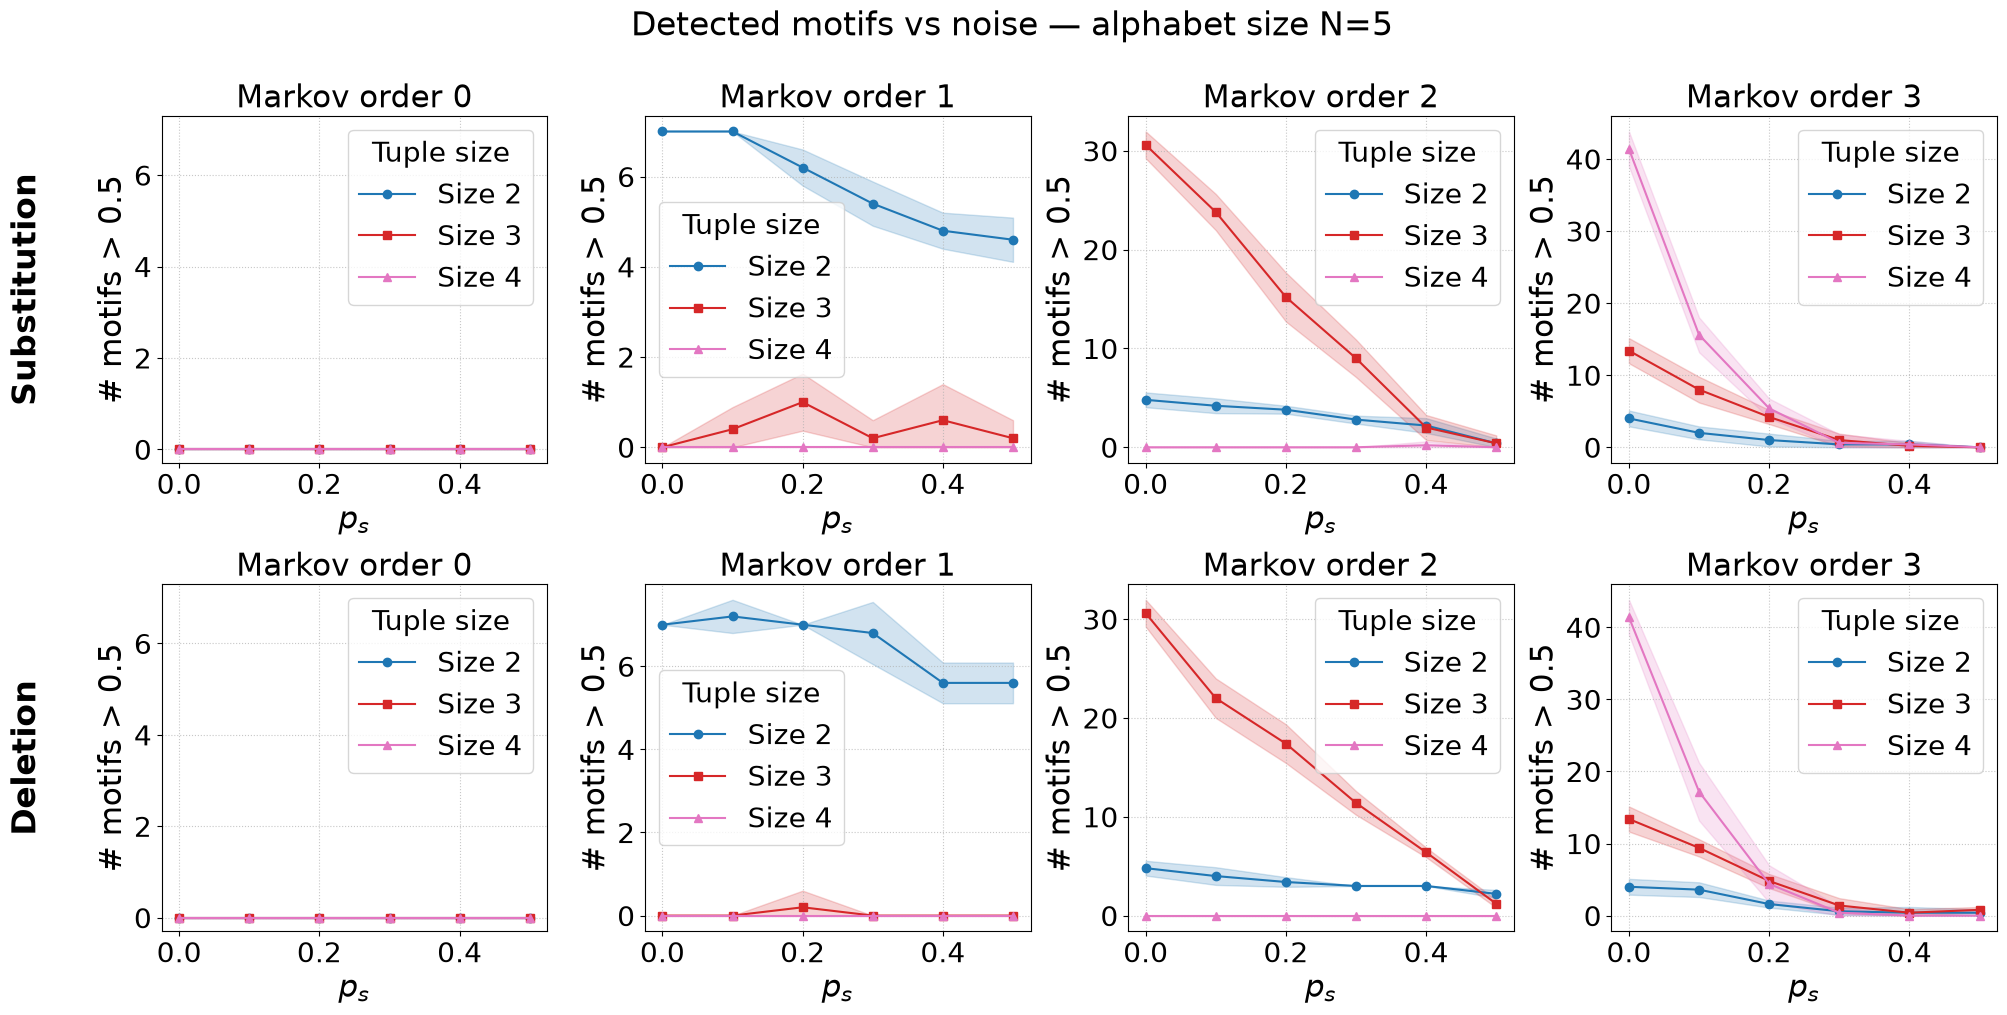

Saved as outputs/figures/motifs_vs_ps_full_N20.svg


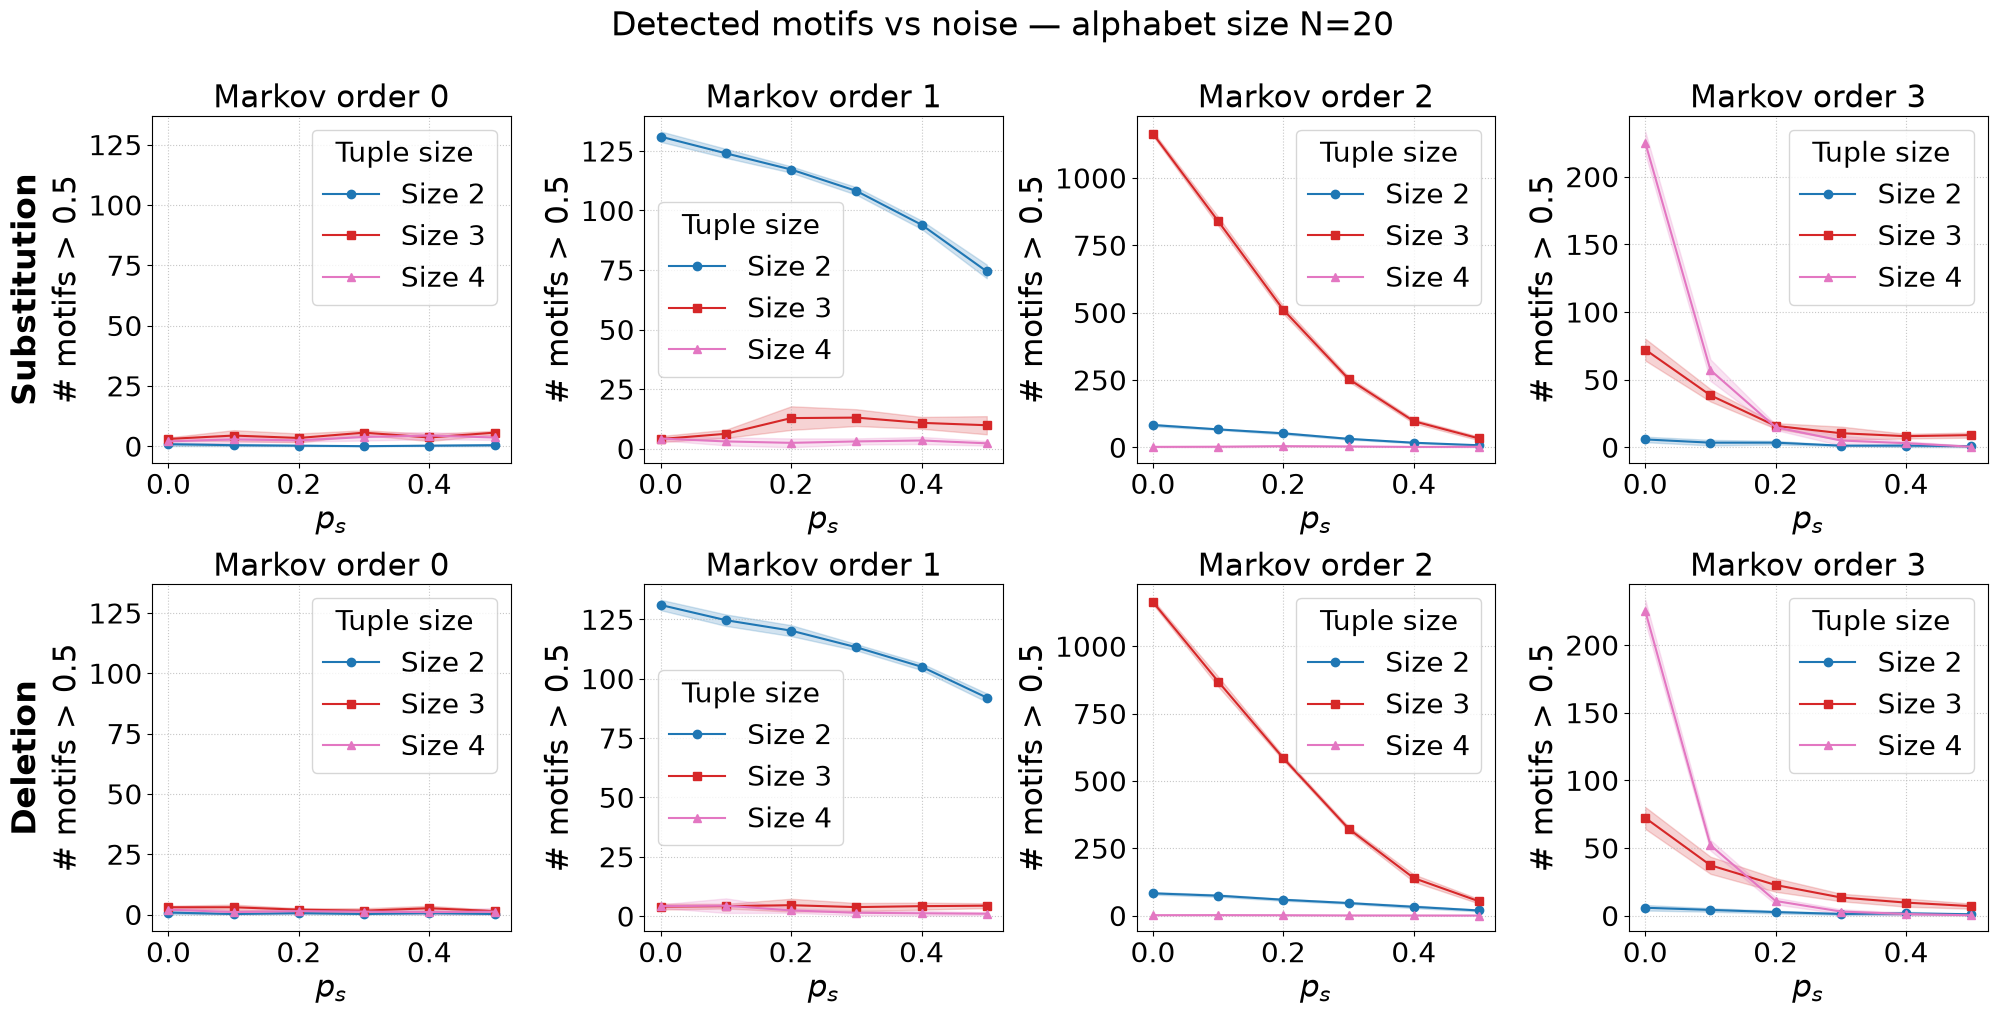

In [28]:
# Reproduce both companion figures (alphabet size 5 and 20), each using the
# file just produced (or cached) by the previous cell for that configuration.
markov_figure_specs = [
    dict(alph_length=5,  sequence_length=5100,
         ylim={("substitution", 2): (-0.3, 7.3), ("deletion", 2): (-0.3, 7.3)}),
    dict(alph_length=20, sequence_length=100100,
         ylim={("substitution", 2): (-7, 137), ("deletion", 2): (-7, 137)}),
]

for spec in markov_figure_specs:
    data_filename = (f"data/markovsequences/motifs_vs_ps"
                     f"_seqlen_{spec['sequence_length']}"
                     f"_alph_{spec['alph_length']}"
                     f"_thresh_0.5.pkl")

    with open(data_filename, 'rb') as f:
        save_dict = pickle.load(f)

    plot_motifs_vs_ps_full(
        save_dict, save_fig=True,
        filename=f"{FIG_DIR}/motifs_vs_ps_full_N{spec['alph_length']}.svg",
        plot_noise_types=["substitution", "deletion"],
        ylim=spec["ylim"],
        # panels not listed get auto-scaled
    )


##### Decay of correlations in the Markov sequences

In [ ]:
### Decay of correlations in the Markov sequences (SM Sec. VIII)
# Mutual information between symbols at distance l, compared with the same sequence randomly shuffled
# (the plug-in estimate is biased upwards, so the shuffled value is the reference "no correlation" level).
# Uses the base sequences saved by the sweep above (after the same 100-symbol burn-in).
def lagged_mutual_information(seq, alph_length, max_lag=10):
    seq = np.asarray(seq)
    mi = []
    for lag in range(1, max_lag + 1):
        joint = np.bincount(seq[:-lag] * alph_length + seq[lag:], minlength=alph_length**2)
        joint = joint.reshape(alph_length, alph_length) / joint.sum()
        px, py = joint.sum(axis=1), joint.sum(axis=0)
        nz = joint > 0
        mi.append(np.sum(joint[nz] * np.log(joint[nz] / np.outer(px, py)[nz])))
    return np.array(mi)

max_lag = 10
n_shuffles_mi = 10
rng_mi = np.random.default_rng(SEED)

for spec in markov_figure_specs:
    data_filename = (f"data/markovsequences/motifs_vs_ps"
                     f"_seqlen_{spec['sequence_length']}"
                     f"_alph_{spec['alph_length']}"
                     f"_thresh_0.5.pkl")
    with open(data_filename, 'rb') as f:
        save_dict = pickle.load(f)
    alph_length = save_dict['alph_length']
    print(f"\nN = {alph_length}: lag at which the mutual information reaches the shuffled level "
          f"(mean + 3 std over {n_shuffles_mi} shuffles)")
    for tuple_length, seqs in save_dict['base_sequences'].items():
        lags = []
        for seq in seqs:
            seq = np.asarray(seq[100:])
            mi = lagged_mutual_information(seq, alph_length, max_lag)
            mi_shuffled = np.array([lagged_mutual_information(rng_mi.permutation(seq), alph_length, max_lag)
                                    for _ in range(n_shuffles_mi)])
            level = mi_shuffled.mean(axis=0) + 3 * mi_shuffled.std(axis=0)
            reached = np.where(mi <= level)[0]
            lags.append(int(reached[0]) + 1 if len(reached) else None)
        print(f"  Markov order {tuple_length - 2}: lag {lags}")



N = 5: lag at which the mutual information reaches the shuffled level (mean + 3 std over 10 shuffles)
  Markov order 0: lag [1, 1, 1, 1, 1]
  Markov order 1: lag [5, 5, 5, 5, 5]
  Markov order 2: lag [5, 7, 5, 4, 7]
  Markov order 3: lag [4, 6, 5, 4, 5]

N = 20: lag at which the mutual information reaches the shuffled level (mean + 3 std over 10 shuffles)
  Markov order 0: lag [1, 1, 1, 1, 1]
  Markov order 1: lag [4, 4, 4, 4, 4]
  Markov order 2: lag [4, 4, 4, 4, 4]
  Markov order 3: lag [4, 4, 4, 4, 4]


### Testing alternative methods on datasets

In [29]:
import pandas as pd
import numpy as np
import yfinance as yf


**Note on the stock data.** Prices are downloaded from Yahoo Finance (via `yfinance`) every time these cells run. The results reported in the paper were obtained with the data downloaded on 2 October 2026; with a later download they can differ slightly, for two reasons:
- Yahoo occasionally revises historical prices (in the last decimals), which can move a few daily changes across the 2% threshold;
- events on the same day are put in random order when building the symbolic sequence (seeded with `SEED`, first cell), so even a small change in the data changes the order of the events on the following days.

The number of significant tuples, and tuples close to the significance threshold, may therefore vary, while the strongest motifs (e.g. the banking and energy triplets) and the overall picture are stable.

##### Stock market — daily fluctuations larger than 2%

An event is recorded for a stock on every day on which its closing price changes by more than 2% with respect
to the previous trading day's close (prices adjusted for splits and dividends). In the signed version the event is
labelled `TICKER+` for a rise and `TICKER-` for a drop. 24 stocks of 8 sectors (3 per sector), 1994–2023.

In [30]:
# 24 stocks, 3 per sector
tickers = [

    #"GE",
    
    # Technology
    "AAPL",  # Apple Inc.
    "MSFT",  # Microsoft Corporation
    "IBM",   # International Business Machines Corporation


    # Chemicals
    "APD",    # Air Products and Chemicals, Inc.
    "PPG",    # PPG Industries, Inc.
    "DD",     # DuPont de Nemours, Inc.


    # Banking
    "JPM",   # JPMorgan Chase & Co.
    "BAC",   # Bank of America Corporation
    "C",     # Citigroup Inc.

    # Entertainment
    "DIS",   # The Walt Disney Company
    "CMCSA", # Comcast Corporation
    "SONY",  # Sony Group Corporation

    # Food & Beverage
    "KO",    # The Coca-Cola Company
    "PEP",   # PepsiCo, Inc.
    "GIS",   # General Mills, Inc.

    # Pharmaceuticals
    "PFE",   # Pfizer Inc.
    "MRK",   # Merck & Co., Inc.
    "JNJ",   # Johnson & Johnson

    # Energy
    "XOM",   # Exxon Mobil Corporation
    "CVX",   # Chevron Corporation
    "COP",   # ConocoPhillips

    # Consumer Goods
    "PG",    # The Procter & Gamble Company
    "CL",    # Colgate-Palmolive Company
    "KMB",   # Kimberly-Clark Corporation
]


In [31]:
# Daily closing prices, adjusted for splits and dividends
prices = yf.download(tickers, start="1994-01-01", end="2024-01-01", auto_adjust=True, progress=False)['Close']
daily_returns = prices.pct_change()   # change with respect to the previous trading day
fluctuation_threshold = 0.02          # 2%

def daily_fluctuation_events(mask, suffix=""):
    """One event per (day, stock) where `mask` is True; the symbol is the ticker (plus `suffix`)."""
    ev = mask.stack()
    ev = ev[ev].reset_index()
    ev.columns = ['timestamp', 'unit_id', 'event']
    ev['unit_id'] = ev['unit_id'] + suffix
    return ev[['timestamp', 'unit_id']].set_index('timestamp')


In [32]:
### Unsigned: an event on every day with a change larger than 2%, in either direction
events_unsigned = daily_fluctuation_events(daily_returns.abs() > fluctuation_threshold)

symba.set_seed(SEED)  # same-day events are put in random order
hyper_symbolic_sequence, spike_symbolic_sequence = symba.events_to_symbolic_sequences(
    pd.Timedelta(days=1), events_unsigned, spacebar=0)
print(f"{len(events_unsigned)} events from {len(set(hyper_symbolic_sequence))} stocks")

js_unsigned, p_unsigned, z_unsigned = symba_and_shuffle_scores(hyper_symbolic_sequence, spike_symbolic_sequence)


5270 events occurred at the same time
32785 events from 24 stocks
Total expected probability for size  1 :  1.0
Total expected probability for size  2 :  0.9999999999999999
Total expected probability for size  3 :  0.9937552616478836


count_sign_thr 18


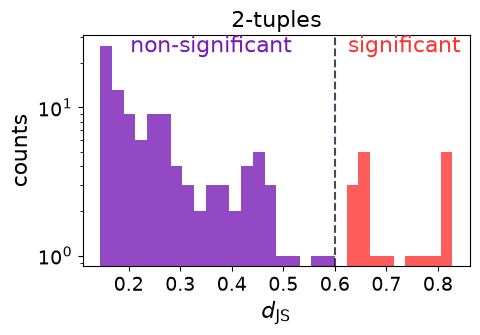

count_sign_thr 6


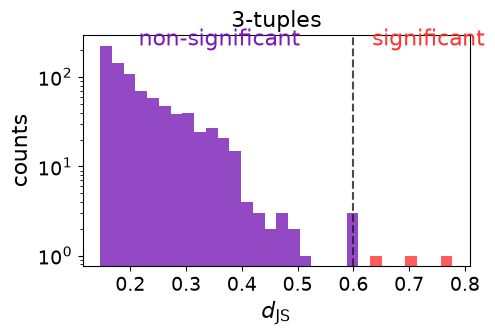


Length 2 (123 tuples)
  spearman_symba_p: 0.996
  pval_spearman_symba_p: 4.14e-127
  spearman_symba_z: 0.998
  pval_spearman_symba_z: 1.35e-151

Length 3 (839 tuples)
  spearman_symba_p: 0.992
  pval_spearman_symba_p: 0.00e+00
  spearman_symba_z: 0.981
  pval_spearman_symba_z: 0.00e+00


In [33]:
for size, label in [(2, '2-tuples'), (3, '3-tuples')]:
    plot_score_histogram(js_unsigned[size], threshold=0.6, title=label)

results = compare_symba_vs_shuffle(js_unsigned, p_unsigned, z_unsigned, lengths=[2, 3])


In [34]:
ticker_to_category = {
    # Technology
    "AAPL": "Technology",
    "MSFT": "Technology",
    "IBM": "Technology",

    # Chemicals
    "DD": "Chemicals",
    "APD": "Chemicals",
    "PPG": "Chemicals",

    # Banking
    "JPM": "Banking",
    "BAC": "Banking",
    "C": "Banking",

    # Entertainment
    "DIS": "Entertainment",
    "CMCSA": "Entertainment",
    "SONY": "Entertainment",

    # Food & Beverage
    "KO": "Food & Beverage",
    "PEP": "Food & Beverage",
    "GIS": "Food & Beverage",

    # Pharmaceuticals
    "PFE": "Pharmaceuticals",
    "MRK": "Pharmaceuticals",
    "JNJ": "Pharmaceuticals",

    # Energy
    "XOM": "Energy",
    "CVX": "Energy",
    "COP": "Energy",

    # Consumer Goods
    "PG": "Consumer Goods",
    "CL": "Consumer Goods",
    "KMB": "Consumer Goods",
}

In [35]:
def same_category_fraction(scores_per_size, ticker_to_category, size, threshold=0.6):
    # significant tuples of distinct stocks: a tuple with a repeated stock, e.g. (SONY, SONY, SONY), is not a hyperedge
    # (rstrip("+-") also makes the function work for the signed symbols, e.g. "AAPL+")
    significant = [t for t, score in scores_per_size[size].items()
                   if score >= threshold and len({s.rstrip("+-") for s in t}) == size]
    if not significant:
        return float("nan"), 0, 0
    same = [t for t in significant
            if len({ticker_to_category[s.rstrip("+-")] for s in t}) == 1]
    return 100 * len(same) / len(significant), len(same), len(significant)


for size in (2, 3):
    pct, n_same, n_tot = same_category_fraction(js_unsigned, ticker_to_category, size)
    print(f"size {size}: {pct:.1f}% same-category ({n_same}/{n_tot})")


size 2: 88.9% same-category (16/18)
size 3: 40.0% same-category (2/5)


In [36]:
### Signed: "+" event on days with a rise larger than 2%, "-" event on days with a drop larger than 2%
events_signed = pd.concat([daily_fluctuation_events(daily_returns > fluctuation_threshold, "+"),
                           daily_fluctuation_events(daily_returns < -fluctuation_threshold, "-")])

symba.set_seed(SEED)  # same-day events are put in random order
hyper_symbolic_sequence, spike_symbolic_sequence = symba.events_to_symbolic_sequences(
    pd.Timedelta(days=1), events_signed, spacebar=0)
print(f"{len(events_signed)} events, {len(set(hyper_symbolic_sequence))} symbols")

js_signed, p_signed, z_signed = symba_and_shuffle_scores(hyper_symbolic_sequence, spike_symbolic_sequence)


5270 events occurred at the same time
32785 events, 48 symbols


Total expected probability for size  1 :  1.0
Total expected probability for size  2 :  0.9982008905423607
Total expected probability for size  3 :  0.8325843055883606


count_sign_thr 107


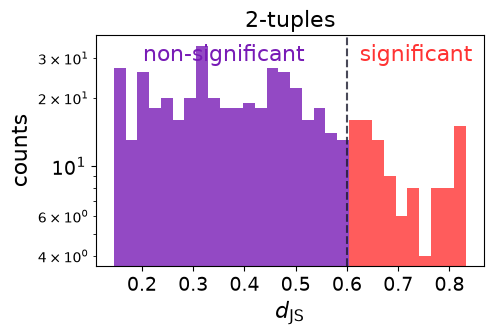

count_sign_thr 3


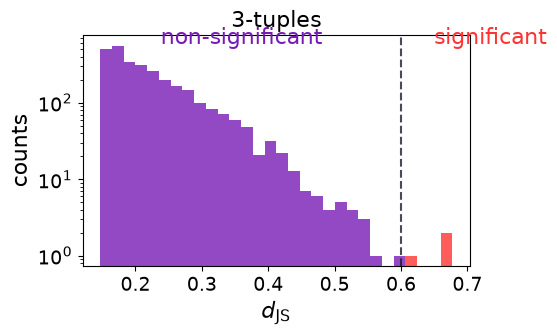

significant pairs: 107 | both rising: 50 | both falling: 57 | opposite directions: 0


In [37]:
for size, label in [(2, '2-tuples'), (3, '3-tuples')]:
    plot_score_histogram(js_signed[size], threshold=0.6, title=label)

# Sign agreement among the significant pairs of two different symbols
significant_pairs = [pair for pair, score in js_signed[2].items() if score >= 0.6 and len(set(pair)) == 2]
both_up   = sum(a.endswith('+') and b.endswith('+') for a, b in significant_pairs)
both_down = sum(a.endswith('-') and b.endswith('-') for a, b in significant_pairs)
print(f"significant pairs: {len(significant_pairs)} | both rising: {both_up} | both falling: {both_down} "
      f"| opposite directions: {len(significant_pairs) - both_up - both_down}")


#### Email dataset

In [38]:
import os
import pandas as pd

In [39]:
#### download from kaggle the first time:
get_data = False  # Set to True if you want to download the dataset
if get_data:
    import zipfile
    import os

    %pip install -q kaggle
    !kaggle datasets download -d wcukierski/enron-email-dataset -p data
    zip_path = "data/enron-email-dataset.zip"  # Adjust the filename if needed
    extract_path = "data"

    assert os.path.exists(zip_path), (
        "Kaggle download failed — make sure the 'kaggle' package is installed "
        "and your API token is set up at ~/.kaggle/kaggle.json "
        "(see https://www.kaggle.com/settings)"
    )

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Unzipping complete!")

In [40]:
## emails sent by each employee from their own mailbox (sender's address contains the folder's surname)

# Load dataset
df = pd.read_csv("data/emails.csv")

# Extract sender and recipients
df[['timestamp', 'sender', 'recipients']] = df['message'].apply(lambda x: pd.Series(extract_email_info(str(x))))

# Extract surname from file path
#df['surname'] = df['file'].apply(lambda x: extract_surname(str(x)))
df[['surname', 'surname_and_initial']] = df['file'].apply(lambda x: pd.Series(extract_surname(str(x))))

# Keep only emails where sender is from Enron
df = df[df['sender'].str.contains(r'@enron\.com$', na=False, regex=True)]

# Keep only emails within the company: all recipients (To, Cc and Bcc) are from Enron
df = df[df['recipients'].apply(all_recipients_enron)]

###df = df[df['recipients'].apply(any_recipient_enron)]

# Keep only emails where sender's email contains their surname
df = df[df.apply(lambda row: row['surname'] in row['sender'], axis=1)]

# Parse the timestamps (e.g. "Mon, 14 May 2001 16:39:00 -0700 (PDT)") as dates, in UTC:
# as text they would be sorted alphabetically instead of in time order
df['timestamp'] = pd.to_datetime(df['timestamp'].str.replace(r"\s*\(.*\)$", "", regex=True),
                                 format="%a, %d %b %Y %H:%M:%S %z", utc=True, errors="coerce")
print(f"unparseable timestamps: {df['timestamp'].isna().sum()}")

# A few emails carry placeholder dates (mostly 1 Jan 1980); the corpus covers 1998-2002
n_before = len(df)
df = df[df['timestamp'] >= pd.Timestamp("1998-01-01", tz="UTC")]
print(f"removed {n_before - len(df)} emails dated before 1998")

# The same email is stored in several folders of the sender's mailbox (sent, _sent_mail,
# all_documents, discussion_threads, ...): keep a single copy of each email
df['subject'] = df['message'].str.extract(r"Subject: (.*)")[0]
df['body'] = df['message'].str.split("\n\n", n=1).str[1]
n_before = len(df)
df = df.drop_duplicates(subset=['timestamp', 'sender', 'recipients', 'subject', 'body'])
print(f"removed {n_before - len(df)} duplicate copies; {len(df)} distinct emails left")

# Keep only relevant columns
df = df[['timestamp', 'surname_and_initial', 'recipients']].dropna()

print(f"{len(df)} emails from {df['surname_and_initial'].nunique()} senders")

unparseable timestamps: 0
removed 201 emails dated before 1998


removed 75687 duplicate copies; 68510 distinct emails left
68510 emails from 143 senders


In [41]:
#df = df.rename(columns={'sender': 'unit_id'})
df = df.rename(columns={'surname_and_initial': 'unit_id'})
#df = df.rename(columns={'sender_surname': 'unit_id'})
# Show processed dataset
df = df.set_index('timestamp')  # Set time as index  

print(f"{len(df)} events from {df.unit_id.nunique()} senders, "
      f"{df.index.min().date()} to {df.index.max().date()}")

68510 events from 143 senders, 1998-10-30 to 2002-06-25


In [42]:
time_bin = pd.Timedelta(days=1)  # Define time bins

# Call function
symba.set_seed(SEED)  # simultaneous emails are put in random order
hyper_symbolic_sequence, spike_symbolic_sequence = symba.events_to_symbolic_sequences(time_bin, df)

# Show result
print(len(set(hyper_symbolic_sequence)), len(hyper_symbolic_sequence))

3092 events occurred at the same time
143 68510


In [43]:
# SYMBA scores and shuffle scores (1000 shuffles) of the pairs and triplets
js_per_size_dict, p_dict_per_size, z_dict_per_size = symba_and_shuffle_scores(
    hyper_symbolic_sequence, spike_symbolic_sequence)


Total expected probability for size  1 :  1.0
Total expected probability for size  2 :  0.9278249971700948
Total expected probability for size  3 :  0.6939487691343182


In [44]:
results = compare_symba_vs_shuffle(js_per_size_dict, p_dict_per_size, z_dict_per_size, lengths=[2, 3])



Length 2 (1794 tuples)
  spearman_symba_p: 0.967
  pval_spearman_symba_p: 0.00e+00
  spearman_symba_z: 0.915
  pval_spearman_symba_z: 0.00e+00

Length 3 (5820 tuples)
  spearman_symba_p: 0.935
  pval_spearman_symba_p: 0.00e+00
  spearman_symba_z: 0.840
  pval_spearman_symba_z: 0.00e+00


### Macro brain areas from Allen dataset

**Note.** To keep the comparison with the shuffle method (1,000 shuffles) feasible in time, this section analyses only part of the recording: 100,000 consecutive spikes (`take_subsequence = True`). The significant tuples reported in the paper are computed with SYMBA on the whole sequence (about 40 million spikes), not on this part: see the last cell of this section.

In [45]:
#### loading the data from the csv file

import csv
hyper_symbolic_sequence = []
spike_symbolic_sequence = []
take_subsequence = True
reshuffle = False


with open('data/sequences_session29_allstimuli_brainareas_multinomial.csv', 'r') as f:
    reader = csv.reader(f)
    next(reader)  # Skip header row
    for row in reader:
        hyper_symbolic_sequence.append(str(row[0]))
        spike_symbolic_sequence.append(str(row[1]))
print(len(hyper_symbolic_sequence),len(spike_symbolic_sequence))


### create the dictionaries to convert the brain areas to numbers and viceversa

print(sorted(set(hyper_symbolic_sequence)))
convert_brain_areas_to_numbers_dict = {}
convert_numbers_to_brain_areas_dict = {}
for i, area in enumerate(sorted(set(hyper_symbolic_sequence))):  # sorted: same labels in every run
    if area != 'space':
        convert_brain_areas_to_numbers_dict[area] = i
        convert_numbers_to_brain_areas_dict[i] = area
    else:
        convert_brain_areas_to_numbers_dict[area] = -1
        convert_numbers_to_brain_areas_dict[-1] = area
hyper_symbolic_sequence_converted = [convert_brain_areas_to_numbers_dict[area] for area in hyper_symbolic_sequence]

####taking only a subsequnence
if take_subsequence:
    start_seq = 200000
    length_seq = 100000
    hyper_symbolic_sequence = hyper_symbolic_sequence_converted[start_seq:start_seq+length_seq]
    spike_symbolic_sequence = spike_symbolic_sequence[start_seq:start_seq+length_seq]
else:
    hyper_symbolic_sequence = hyper_symbolic_sequence_converted

### reshuffling the sequence and preparing a fake spike sequence
if reshuffle:
    symba.set_seed(SEED)
    time_bin = 2
    for i in range(2):
        random.shuffle(hyper_symbolic_sequence)
    random.shuffle(hyper_symbolic_sequence)
    fake_spikes = [i for i in range(len(hyper_symbolic_sequence))]
    time_gap = 0
    for el_id, element in enumerate(hyper_symbolic_sequence):
        if element == -1:
            fake_spikes[el_id] = -1
            time_gap += time_bin + 1
        else:
            fake_spikes[el_id] = time_gap + el_id
    spike_symbolic_sequence = fake_spikes

40133703 40133703
['APN', 'CA1', 'CA2', 'CA3', 'DG', 'IGL', 'IntG', 'LP', 'POL', 'PPT', 'SUB', 'VISal', 'VISam', 'VISl', 'VISp', 'VISpm', 'VISrl', 'ZI', 'space']


In [46]:
len(hyper_symbolic_sequence)

100000

In [47]:
symba.set_seed(SEED)  # the shuffles are random
# SYMBA scores and shuffle scores (1000 shuffles) of the pairs and triplets
js_per_size_dict, p_dict_per_size, z_dict_per_size = symba_and_shuffle_scores(
    hyper_symbolic_sequence, spike_symbolic_sequence)


Total expected probability for size  1 :  1.0
Total expected probability for size  2 :  0.999964691
Total expected probability for size  3 :  0.9990611770901139


In [48]:
results = compare_symba_vs_shuffle(js_per_size_dict, p_dict_per_size, z_dict_per_size, lengths=[2, 3])



Length 2 (73 tuples)
  spearman_symba_p: 0.996
  pval_spearman_symba_p: 4.01e-77
  spearman_symba_z: 0.992
  pval_spearman_symba_z: 6.93e-65

Length 3 (370 tuples)
  spearman_symba_p: 0.985
  pval_spearman_symba_p: 2.89e-283
  spearman_symba_z: 0.957
  pval_spearman_symba_z: 3.87e-200


##### Whole session (significant tuples reported in the paper)
SYMBA on the whole sequence (about 40 million spikes), without the shuffle comparison. The package counts tuples by storing every window of the sequence, which needs too much memory for a sequence this long; here the windows are counted with NumPy instead. The counts are identical, and everything else uses the package functions. This shortcut is not part of the runtime comparison with the shuffle method.

In [49]:
def count_windows(sequence, max_size=3):
    """Counts and probabilities of all windows of 1..max_size consecutive symbols (as the package computes them)."""
    x = np.asarray(sequence)
    alphabet = np.unique(x)
    codes = np.searchsorted(alphabet, x).astype(np.int64)  # symbol -> 0..A-1
    A, L = len(alphabet), len(codes)
    counts, probs = {}, {}
    for k in range(1, max_size + 1):
        window = np.zeros(L - k + 1, dtype=np.int64)  # each window as one base-A number
        for j in range(k):
            window = window * A + codes[j:L - k + 1 + j]
        values, n = np.unique(window, return_counts=True)
        for value, count in zip(values.tolist(), n.tolist()):
            digits = []
            for _ in range(k):
                value, d = divmod(value, A)
                digits.append(alphabet[d].item())
            key = tuple(reversed(digits))
            counts[key] = count
            probs[key] = count / (L - k + 1)
    return counts, probs

full_sequence = hyper_symbolic_sequence_converted          # the whole session, built by the loading cell
directed_counts, directed_probs = count_windows(full_sequence, max_size=3)
observed_counts_full = symba.converter_directed_to_undirected(directed_counts)
expected_probs_full = symba.expected_undirected_probability(directed_probs)
quantiles_list = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
                  0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]   # as in the other sections
js_full = symba.js_score_per_size(full_sequence, observed_counts_full, expected_probs_full, max_size=3,
                                  positive_js=1, smooth_prior=1., number_of_points=0,
                                  quantiles_list=quantiles_list, with_space=0)

# hyperedges: significant tuples (score >= 0.6) of distinct brain areas
areas = [s for s in set(full_sequence) if s != -1]
print(f"N = {len(areas)} brain areas, {len(full_sequence):,} spikes")
for size in (2, 3):
    significant = [t for t, score in js_full[size].items() if score >= 0.6]
    distinct = [t for t in significant if len(set(t)) == size]
    print(f"E{size} = {len(distinct)} (significant {size}-tuples of distinct areas; "
          f"{len(significant) - len(distinct)} more contain the same area twice)")


Total expected probability for size  1 :  1.0
Total expected probability for size  2 :  0.9999921511388615
Total expected probability for size  3 :  0.9999978851126406
N = 18 brain areas, 40,133,703 spikes
E2 = 51 (significant 2-tuples of distinct areas; 10 more contain the same area twice)
E3 = 85 (significant 3-tuples of distinct areas; 130 more contain the same area twice)
